<a href="https://colab.research.google.com/github/sovdevs/7406_cbb/blob/master/Copy_of_Practice_Session_01_Student_Exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PS 01: Python and ML Foundations

Welcome to the first Intro2LLM practice session. We will connect core Python operations to the data flow used in later NLP and LLM systems.

## Learning objectives

By the end of this session, you will be able to:

1. Use Python variables, operators, conditionals, loops, and functions.
2. Normalize, split, inspect, and count text with built-in string operations.
3. Choose and manipulate lists, dictionaries, text files, and JSON data.
4. Reason about NumPy/PyTorch shapes, axes, matrix operations, and broadcasting.
5. Explain the roles of training, development, and test data.
6. Define, train, and evaluate a small PyTorch multi-layer perceptron (MLP).

## How we will work

We follow the same cycle throughout the notebook:

**explain → demonstrate → implement → inspect → compare & interpret**

Run each guided example, predict important outputs before revealing them, and then complete the following four focused subtasks.

| Subtask | Focus | Observable result |
|---|---|---|
| **1.1 Word Frequencies** | strings, lists, `Counter` | ranked word counts |
| **1.2 JSON Parsing** | structured data, safe lookup | extracted text and total words |
| **2.1 Core Array/Tensor Ops** | reshape, transpose, matmul, axes, broadcasting | checked shapes and broadcast result |
| **2.2 PyTorch MLP** | modules, loss, gradients, evaluation | decreasing loss and predictions |

## 1. Jupyter and Colab fundamentals

A notebook mixes **Markdown cells** (explanations) with **code cells** (executable Python). In Google Colab:

- `Shift + Enter` runs a cell and moves to the next one.
- `Ctrl/Cmd + Enter` runs a cell and stays on it.
- The number in `In [ ]` records execution order; `In [*]` means that a cell is still running.
- Variables remain available only after the cell that creates them has run.

**Important:** notebooks are stateful. Running cells out of order can hide bugs. Before you finish, use **Runtime → Restart session and run all** and check that the notebook works from top to bottom.

Files created below (`example.txt`, `data.json`, and `cats.csv`) are stored in the temporary Colab runtime and disappear when that runtime is reset.

**Walkthrough cells.** Some code cells are followed by a **Walkthrough** cell. It reruns the code above, or a shortened copy of it, and lets you step through it line by line: the highlighted line has just run, the variables panel marks inputs and anything new or changed, and the output panel shows what has been printed so far. Use **Next →**, **Play**, the slider, or the ← / → keys. An **Explorer** cell lets you try your own inputs. Their code is collapsed because only the output matters (in Colab, click **Show code** if you are curious). Run the setup cell below once before using them.

In [ ]:
# @title Setup: walkthrough tools (run once; you do not need to read this cell)
# Defines trace_code(), trace_call(), slice_explorer(), and network_walkthrough() for the Walkthrough and Explorer cells below.
# They run the code, record what happens, and draw an interactive player.
_I2L_VIZ_SOURCE = r'''
# Intro2LLM step-through visualizer: runs real code, records every executed line,
# and renders an interactive player (code | variables | printed output).
import builtins
import contextlib
import hashlib
import html
import io
import json
import keyword
import re
import sys
import textwrap
import tokenize
import types
import uuid

from IPython.display import HTML, display

_MAX_STEPS = 400
_HEADERS = ("for ", "if ", "elif ", "while ")


def _code_part(line):
    """Line text without a trailing comment (good enough for loop/if headers)."""
    return re.sub(r"\s+#[^'\"]*$", "", line).strip()


# ----------------------------------------------------------------------------- values
def _short(text, limit):
    return text if len(text) <= limit else text[: limit - 1] + "…"


def _num(x):
    if isinstance(x, float):
        return f"{x:.4g}"
    return repr(x) if isinstance(x, str) else str(x)


def _sig(text):
    """Short fingerprint used by the player to detect changed values."""
    return hashlib.md5(text.encode()).hexdigest()[:10]


def _view(value):
    """Describe a value so the player can draw it (array grid, dict table, list chips, text)."""
    type_name = type(value).__name__
    shape = getattr(value, "shape", None)
    if shape is not None and hasattr(value, "tolist") and not isinstance(value, type):
        dims = [int(d) for d in shape]
        view = {"kind": "array", "type": type_name, "shape": dims,
                "dtype": str(getattr(value, "dtype", "")).replace("torch.", ""), "sig": _sig(repr(value))}
        data = value.tolist()
        if len(dims) == 0:
            view["rows"] = [[_num(data)]]
        elif len(dims) == 1:  # long vectors: first 12 values, then "…"
            cells = [_num(x) for x in data[:16 if dims[0] <= 16 else 12]]
            view["rows"] = [cells + (["…"] if dims[0] > 16 else [])]
        elif len(dims) == 2:  # large matrices: first rows/columns, then "…" / "⋮"
            n_rows = dims[0] if dims[0] <= 8 else 5
            n_cols = dims[1] if dims[1] <= 10 else 8
            rows = [[_num(x) for x in row[:n_cols]] + (["…"] if dims[1] > n_cols else []) for row in data[:n_rows]]
            view["rows"] = rows + ([["⋮"] * len(rows[0])] if dims[0] > n_rows else [])
        else:
            view["kind"], view["text"] = "text", _short(" ".join(repr(value).split()), 140)
        return view
    if isinstance(value, dict) and len(value) <= 14:
        return {"kind": "dict", "type": type_name, "sig": _sig(repr(value)),
                "items": [[_short(repr(k), 28), _short(repr(v), 40)] for k, v in value.items()]}
    if isinstance(value, (list, tuple)) and len(value) <= 24:
        return {"kind": "seq", "type": type_name, "sig": _sig(repr(value)),
                "items": [_short(repr(x), 28) for x in value]}
    text = repr(value)
    return {"kind": "text", "type": type_name, "text": _short(text, 140), "sig": _sig(text)}


def _visible(name, value):
    hidden_types = (types.ModuleType, types.FunctionType, types.BuiltinFunctionType, type)
    return not name.startswith("_") and not isinstance(value, hidden_types)


# ----------------------------------------------------------------------------- source
def _highlight(lines):
    """Return one HTML string per source line with light syntax colouring."""
    marks = [[""] * len(line) for line in lines]
    builtin_names = set(dir(builtins))
    string_types = {tokenize.STRING} | {getattr(tokenize, n) for n in ("FSTRING_START", "FSTRING_MIDDLE", "FSTRING_END")
                                        if hasattr(tokenize, n)}
    try:
        toks = list(tokenize.generate_tokens(io.StringIO("\n".join(lines) + "\n").readline))
    except (tokenize.TokenError, IndentationError, SyntaxError):
        toks = []
    for tok in toks:
        cls = ""
        if tok.type == tokenize.COMMENT:
            cls = "cm"
        elif tok.type in string_types:
            cls = "st"
        elif tok.type == tokenize.NAME and keyword.iskeyword(tok.string):
            cls = "kw"
        elif tok.type == tokenize.NAME and tok.string in builtin_names:
            cls = "bi"
        elif tok.type == tokenize.NUMBER:
            cls = "nu"
        if not cls:
            continue
        (r0, c0), (r1, c1) = tok.start, tok.end
        for r in range(r0, r1 + 1):
            if r - 1 >= len(lines):
                break
            start = c0 if r == r0 else 0
            end = c1 if r == r1 else len(lines[r - 1])
            for c in range(start, min(end, len(lines[r - 1]))):
                marks[r - 1][c] = cls
    out = []
    for line, mark in zip(lines, marks):
        parts, i = [], 0
        while i < len(line):
            j = i
            while j < len(line) and mark[j] == mark[i]:
                j += 1
            chunk = html.escape(line[i:j])
            parts.append(f'<span class="{mark[i]}">{chunk}</span>' if mark[i] else chunk)
            i = j
        out.append("".join(parts) or " ")
    return out


def _block_ends(lines):
    """For each header line (for/if/while ...:), the last line number of its indented body."""
    def indent(s):
        return len(s) - len(s.lstrip())

    ends = {}
    for i, line in enumerate(lines):
        text = _code_part(line)
        if text.startswith(_HEADERS) and text.endswith(":"):
            end = i + 1
            for j in range(i + 1, len(lines)):
                body = lines[j].strip()
                if not body or body.startswith("#"):
                    continue
                if indent(lines[j]) <= indent(line):
                    break
                end = j + 1
            ends[i + 1] = end
    return ends


# ----------------------------------------------------------------------------- tracing
class _Recorder:
    def __init__(self, lines, offset, notes, watch, hide, inputs):
        self.lines, self.offset = lines, offset
        self.notes, self.watch, self.hide, self.inputs = notes or {}, watch, set(hide or ()), inputs
        self.block_ends = _block_ends(lines)
        self.steps, self.pending, self.exc = [], None, None
        self.buffer = io.StringIO()
        self.truncated = False

    # values ------------------------------------------------------------------
    def snapshot(self, local_vars, global_vars=None):
        if not self.watch:
            names = [n for n, v in local_vars.items() if _visible(n, v) and n not in self.hide]
            return [[n, _view(local_vars[n]), n in self.inputs] for n in names]
        shown = []
        for expr in self.watch:  # watch entries may be names or expressions
            try:
                value = eval(expr, global_vars if global_vars is not None else {}, dict(local_vars))
            except Exception:
                continue  # not defined yet at this step
            shown.append([expr, _view(value), expr in self.inputs])
        return shown

    def user_note(self, key_text, frame):
        for key, template in self.notes.items():
            if key == "return":  # reserved for the final return-value step
                continue
            if (isinstance(key, int) and key == key_text) or (isinstance(key, str) and key in str(key_text)):
                try:
                    return eval("f" + repr(template), frame.f_globals, dict(frame.f_locals))
                except Exception:
                    return template
        return ""

    def auto_note(self, line, next_line, frame):
        if self.exc:
            note, self.exc = f"raises {self.exc}", None
            return note
        text = _code_part(self.lines[line - 1])
        if line not in self.block_ends:
            return ""
        entered = next_line is not None and line < next_line <= self.block_ends[line]
        if text.startswith("for "):
            target = text[4:].split(" in ", 1)[0].strip()
            if not entered:
                return "no items left → the loop ends"
            try:
                value = eval(target, frame.f_globals, dict(frame.f_locals))
                return f"next item: {target} = {_short(repr(value), 50)}"
            except Exception:
                return "next item"
        condition = text.split(" ", 1)[1][:-1].strip()
        verdict = "True" if entered else "False"
        if text.startswith("while "):
            return f"{condition} → {verdict}: " + ("run the loop body" if entered else "leave the loop")
        return f"{condition} → {verdict}: " + ("run the indented block" if entered else "skip the block")

    # events ------------------------------------------------------------------
    def finalize(self, frame, next_line):
        if self.pending is None:
            return
        line, self.pending = self.pending, None
        step = {"line": line, "vars": self.snapshot(frame.f_locals, frame.f_globals), "out": len(self.buffer.getvalue()),
                "note": self.user_note(self.lines[line - 1], frame),
                "auto": self.auto_note(line, next_line, frame)}
        # Inlined comprehensions re-trigger the same line; keep only the finished state.
        if self.steps and self.steps[-1]["line"] == line and self.steps[-1].get("kind") != "start":
            self.steps[-1] = step
        elif len(self.steps) < _MAX_STEPS:
            self.steps.append(step)
        else:
            self.truncated = True

    def local_tracer(self, frame, event, arg):
        line = frame.f_lineno - self.offset
        if event == "line":
            self.finalize(frame, line)
            self.pending = line
        elif event == "exception":
            self.exc = f"{arg[0].__name__}: {arg[1]}"
        elif event == "return":
            self.finalize(frame, None)
            self.return_frame = frame
        return self.local_tracer


def _run(recorder, should_trace, runner):
    def global_tracer(frame, event, arg):
        return recorder.local_tracer if event == "call" and should_trace(frame) else None

    previous = sys.gettrace()
    error = None
    result = None
    with contextlib.redirect_stdout(recorder.buffer):
        sys.settrace(global_tracer)
        try:
            result = runner()
        except Exception as exc:  # shown inside the player instead of stopping the notebook
            error = f"{type(exc).__name__}: {exc}"
        finally:
            sys.settrace(previous)
    return result, error


def trace_call(func, *args, title=None, intro="", notes=None, watch=None, hide=None, **kwargs):
    """Call `func(*args, **kwargs)` and show every executed line of its body."""
    import inspect
    source = textwrap.dedent(inspect.getsource(func))
    lines = source.rstrip("\n").split("\n")
    offset = func.__code__.co_firstlineno - 1
    bound = inspect.signature(func).bind(*args, **kwargs)
    bound.apply_defaults()
    rec = _Recorder(lines, offset, notes, watch, hide, inputs=set(bound.arguments))
    start_vars = [[n, _view(v), True] for n, v in bound.arguments.items()]
    if watch:
        start_vars = rec.snapshot(bound.arguments, func.__globals__)
    rec.steps.append({"kind": "start", "line": None, "vars": start_vars, "out": 0,
                      "note": intro or f"Call {func.__name__}(...) with the inputs shown on the right.", "auto": ""})
    result, error = _run(rec, lambda f: f.f_code is func.__code__, lambda: func(*args, **kwargs))
    _finish(rec, title or f"Step through {func.__name__}()", lines, result, error, returns=True)


def trace_code(code, env=None, title="Step through the code", intro="", notes=None, watch=None, hide=None):
    """Execute a code snippet line by line. `env` provides the input variables (and imports)."""
    source = textwrap.dedent(code).strip("\n")
    lines = source.split("\n")
    namespace = dict(env or {})
    inputs = {n for n, v in namespace.items() if _visible(n, v)}
    rec = _Recorder(lines, 0, notes, watch, hide, inputs=inputs)
    compiled = compile(source, "<i2l-trace>", "exec")
    rec.steps.append({"kind": "start", "line": None, "out": 0, "auto": "",
                      "vars": rec.snapshot(namespace, namespace),
                      "note": intro or ("Before running: these are the inputs." if inputs
                                        else "Nothing has run yet. Press Next → to run line 1.")})
    _, error = _run(rec, lambda f: f.f_code is compiled, lambda: exec(compiled, namespace))
    _finish(rec, title, lines, None, error, returns=False)


def _finish(rec, title, lines, result, error, returns):
    last = rec.steps[-1]
    if error:
        rec.steps.append({"kind": "error", "line": last["line"], "vars": last["vars"],
                          "out": len(rec.buffer.getvalue()), "note": f"The code stopped with {error}", "auto": ""})
    elif returns:
        rec.steps.append({"kind": "return", "line": last["line"], "vars": last["vars"],
                          "out": len(rec.buffer.getvalue()), "ret": _view(result),
                          "note": rec.notes.get("return", "") or "The function returns this value to the caller.",
                          "auto": ""})
    data = {"title": title, "code": _highlight(lines), "steps": rec.steps,
            "stdout": rec.buffer.getvalue(), "truncated": rec.truncated}
    _render(data)


# ----------------------------------------------------------------------------- HTML
_CSS = """
#ID{--bd:#dfe3e8;--mut:#667085;--acc:#b45309;--accS:#fff7ed;--new:#f0fdf4;--chg:#fffbeb;
 font-family:Inter,ui-sans-serif,system-ui,-apple-system,"Segoe UI",sans-serif;color:#18212f;background:#fff;
 border:1px solid var(--bd);border-radius:14px;padding:14px;max-width:1150px;outline:none;color-scheme:light;--h:440px}
#ID *{box-sizing:border-box}
#ID .hd{display:flex;justify-content:space-between;gap:12px;align-items:center;flex-wrap:wrap;margin-bottom:10px}
#ID .tt{font-size:17px;font-weight:750}
#ID .pill{border:1px solid var(--bd);background:#f7f8fa;border-radius:999px;padding:5px 10px;font-size:12px;font-weight:700}
#ID .grid{display:grid;grid-template-columns:minmax(0,1fr) minmax(0,1fr);gap:12px;align-items:stretch}
#ID .card{border:1px solid var(--bd);border-radius:11px;overflow:hidden;background:#fff;min-width:0}
#ID .ct{padding:7px 11px;border-bottom:1px solid var(--bd);font-size:11px;font-weight:750;color:var(--mut);
 text-transform:uppercase;letter-spacing:.04em;background:#f7f8fa}
#ID .codecard{display:flex;flex-direction:column;height:var(--h)}
#ID .code{background:#111827;color:#e5e7eb;font:12.5px/1.6 ui-monospace,SFMono-Regular,Menlo,Consolas,monospace;
 flex:1;min-height:0;overflow:auto;padding:8px 0;position:relative}
#ID .ln{display:grid;grid-template-columns:34px 1fr;white-space:pre;border-left:4px solid transparent;padding-right:10px}
#ID .ln>i{font-style:normal;color:#6b7280;text-align:right;padding-right:10px;user-select:none}
#ID .ln.on{background:rgba(245,158,11,.2);border-left-color:#f59e0b}
#ID .ln.done>i{color:#9ca3af}
#ID .kw{color:#c084fc}#ID .st{color:#86efac}#ID .cm{color:#7c8594;font-style:italic}#ID .bi{color:#93c5fd}#ID .nu{color:#fbbf24}
#ID .side{display:flex;flex-direction:column;gap:10px;min-width:0;height:var(--h)}
#ID .varcard{flex:1;min-height:0;display:flex;flex-direction:column}
#ID .outcard{flex:none}
#ID .msg{flex:none;border-left:4px solid #2563eb;background:#eff6ff;border-radius:8px;padding:8px 10px;font-size:13px;line-height:1.45;min-height:46px}
#ID .msg .where{font-size:11px;color:var(--mut);font-weight:700;text-transform:uppercase;letter-spacing:.03em}
#ID .msg .auto{margin-top:4px;font:12px ui-monospace,Menlo,monospace;color:#1e3a8a}
#ID .msg.err{border-left-color:#b42318;background:#fef2f2}
#ID .msg.ret{border-left-color:#15803d;background:#f0fdf4}
#ID .vars{padding:8px;display:flex;flex-direction:column;gap:6px;flex:1;min-height:0;overflow-y:auto;position:relative}
#ID .var{flex:none;border:1px solid var(--bd);border-radius:8px;padding:6px 8px;transition:background .25s;min-width:0}
#ID .val{overflow-x:auto;max-width:100%}
#ID .var.new{background:var(--new);border-color:#86efac}
#ID .var.chg{background:var(--chg);border-color:#fcd34d}
#ID .vh{display:flex;gap:6px;align-items:baseline;flex-wrap:wrap;font-size:12px;margin-bottom:3px}
#ID .vn{font:700 12.5px ui-monospace,Menlo,monospace}
#ID .ty{color:var(--mut);font-size:11px}
#ID .tag{font-size:10px;font-weight:750;border-radius:999px;padding:1px 6px;text-transform:uppercase}
#ID .tag.in{background:#e0e7ff;color:#3730a3}#ID .tag.new{background:#dcfce7;color:#166534}#ID .tag.chg{background:#fef3c7;color:#92400e}
#ID .tag.out{background:#dcfce7;color:#166534}
#ID .mono{font:12px/1.45 ui-monospace,Menlo,monospace;word-break:break-word}
#ID .chips{display:flex;flex-wrap:wrap;gap:4px}
#ID .chip{border:1px solid #cfd4dc;border-radius:6px;padding:2px 6px;font:12px ui-monospace,Menlo,monospace;background:#fff;position:relative}
#ID .chip sub{color:var(--mut);font-size:9px;margin-left:3px}
#ID .chip.hl,#ID td.hl{background:#fde68a;border-color:#f59e0b}
#ID table{border-collapse:collapse;font:12px ui-monospace,Menlo,monospace}
#ID td{border:1px solid #e5e7eb;padding:2px 7px;text-align:right}
#ID .kv td{text-align:left}
#ID .out{background:#0b1020;color:#d1d5db;font:12px/1.5 ui-monospace,Menlo,monospace;white-space:pre-wrap;
 padding:8px 10px;height:110px;overflow:auto}
@media (max-width:560px){#ID .grid{grid-template-columns:1fr}#ID .codecard,#ID .side{height:auto}
 #ID .code{max-height:340px}#ID .vars{max-height:320px}}
#ID .out b{color:#fde68a;font-weight:600}
#ID .ctl{display:flex;gap:7px;align-items:center;flex-wrap:wrap;margin-top:10px}
#ID button{border:1px solid var(--bd);background:#fff;color:#18212f;border-radius:8px;min-height:34px;padding:5px 11px;
 font-weight:700;font-size:13px;cursor:pointer}
#ID button.pri{background:var(--acc);border-color:var(--acc);color:#fff}
#ID button:disabled{opacity:.4;cursor:default}
#ID input[type=range]{flex:1;min-width:120px;accent-color:#b45309}
#ID .hint{color:var(--mut);font-size:11px}
"""

_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const S = D.steps, $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const codeBox = $(".code");
  codeBox.innerHTML = D.code.map((h, i) => `<div class="ln" data-n="${i+1}"><i>${i+1}</i><span>${h}</span></div>`).join("");
  const lines = [...codeBox.children];
  // Height: fit the code (within limits) so code and state stay visible side by side.
  const codeHeight = D.code.length * 20 + 50;
  root.style.setProperty("--h", Math.max(D.stdout ? 420 : 340, Math.min(520, codeHeight)) + "px");
  if (!D.stdout) $(".outcard").style.display = "none";
  let k = 0, timer = null;

  function value(v, prev) {
    if (v.kind === "array") {
      const p = prev && prev.kind === "array" && JSON.stringify(prev.shape) === JSON.stringify(v.shape) ? prev.rows : null;
      return `<table>${v.rows.map((r, i) => `<tr>${r.map((x, j) =>
        `<td class="${p && p[i][j] !== x ? "hl" : ""}">${esc(x)}</td>`).join("")}</tr>`).join("")}</table>`;
    }
    if (v.kind === "dict") {
      if (!v.items.length) return `<span class="mono" style="color:var(--mut)">{} (empty)</span>`;
      const old = new Map(prev && prev.kind === "dict" ? prev.items : []);
      return `<table class="kv">${v.items.map(([a, b]) =>
        `<tr><td class="${prev && old.get(a) !== b ? "hl" : ""}">${esc(a)}</td><td class="${prev && old.get(a) !== b ? "hl" : ""}">${esc(b)}</td></tr>`).join("")}</table>`;
    }
    if (v.kind === "seq") {
      if (!v.items.length) return `<span class="mono" style="color:var(--mut)">${v.type === "tuple" ? "()" : "[]"} (empty)</span>`;
      const p = prev && prev.kind === "seq" ? prev.items : null;
      return `<div class="chips">${v.items.map((x, i) =>
        `<span class="chip ${p && p[i] !== x ? "hl" : ""}">${esc(x)}<sub>${i}</sub></span>`).join("")}</div>`;
    }
    return `<div class="mono">${esc(v.text)}</div>`;
  }

  function typeLabel(v) {
    if (v.kind === "array") return `${v.type} · shape (${v.shape.join(", ")}${v.shape.length === 1 ? "," : ""}) · ${v.dtype}`;
    if (v.kind === "dict" || v.kind === "seq") return `${v.type} · len ${v.items.length}`;
    return v.type;
  }

  function render() {
    const s = S[k], prevStep = k > 0 ? S[k - 1] : null;
    const prevVars = new Map(prevStep ? prevStep.vars.map(([n, v]) => [n, v]) : []);
    const ran = new Set(S.slice(1, k + 1).map(x => x.line));
    lines.forEach(el => {
      const n = +el.dataset.n;
      el.classList.toggle("on", n === s.line);
      el.classList.toggle("done", ran.has(n) && n !== s.line);
    });
    const on = lines[(s.line || 1) - 1];
    if (on && s.line) {
      const top = on.offsetTop;
      if (top < codeBox.scrollTop || top > codeBox.scrollTop + codeBox.clientHeight - 30)
        codeBox.scrollTop = Math.max(0, top - codeBox.clientHeight / 3);
    }

    const msg = $(".msg");
    msg.className = "msg" + (s.kind === "error" ? " err" : s.kind === "return" ? " ret" : "");
    const where = s.kind === "start" ? "Before running" : s.kind === "return" ? "Return value"
                : s.kind === "error" ? "Error" : `Line ${s.line} just ran`;
    msg.innerHTML = `<div class="where">${where}</div>${s.note ? `<div>${esc(s.note)}</div>` : ""}` +
                    (s.auto ? `<div class="auto">▸ ${esc(s.auto)}</div>` : "");

    let varsHtml = s.vars.map(([n, v, isIn]) => {
      const prev = prevVars.get(n);
      const state = !prevStep || s.kind === "start" ? "" : !prev ? "new" : prev.sig !== v.sig ? "chg" : "";
      const tags = (isIn ? `<span class="tag in">input</span>` : "") +
                   (state === "new" ? `<span class="tag new">new</span>` : state === "chg" ? `<span class="tag chg">changed</span>` : "");
      return `<div class="var ${state}"><div class="vh"><span class="vn">${esc(n)}</span><span class="ty">${esc(typeLabel(v))}</span>${tags}</div><div class="val">${value(v, state === "chg" ? prev : null)}</div></div>`;
    }).join("");
    if (s.ret) varsHtml = `<div class="var new"><div class="vh"><span class="vn">return</span><span class="ty">${esc(typeLabel(s.ret))}</span><span class="tag out">output</span></div><div class="val">${value(s.ret)}</div></div>` + varsHtml;
    const varsBox = $(".vars");
    varsBox.innerHTML = varsHtml || `<span class="hint">No variables yet.</span>`;
    const focus = varsBox.querySelector(".var.new, .var.chg");
    varsBox.scrollTop = focus ? Math.max(0, focus.offsetTop - 8) : 0;

    const before = prevStep ? prevStep.out : 0;
    const out = D.stdout.slice(0, before) ;
    const fresh = D.stdout.slice(before, s.out);
    const outBox = $(".out");
    outBox.innerHTML = esc(out) + (fresh ? `<b>${esc(fresh)}</b>` : "") || `<span style="color:#6b7280">(nothing printed yet)</span>`;
    outBox.scrollTop = outBox.scrollHeight;

    $(".pill").textContent = `Step ${k + 1} / ${S.length}`;
    $("input").value = k;
    $(".b-first").disabled = $(".b-back").disabled = k === 0;
    $(".b-next").disabled = k === S.length - 1;
  }

  const go = i => { k = Math.max(0, Math.min(S.length - 1, i)); render(); };
  const stop = () => { clearInterval(timer); timer = null; $(".b-play").textContent = "Play"; };
  $("input").max = S.length - 1;
  $(".b-first").onclick = () => { stop(); go(0); };
  $(".b-back").onclick = () => { stop(); go(k - 1); };
  $(".b-next").onclick = () => { stop(); go(k + 1); };
  $("input").oninput = e => { stop(); go(+e.target.value); };
  $(".b-play").onclick = () => {
    if (timer) return stop();
    if (k === S.length - 1) go(0);
    $(".b-play").textContent = "Pause";
    timer = setInterval(() => (k >= S.length - 1 ? stop() : go(k + 1)), 900);
  };
  root.addEventListener("keydown", e => {
    if (e.key === "ArrowRight") { stop(); go(k + 1); e.preventDefault(); }
    if (e.key === "ArrowLeft") { stop(); go(k - 1); e.preventDefault(); }
  });
  render();
  } catch (err) {
    const box = document.createElement("div");
    box.className = "hint";
    box.style.cssText = "color:#b42318;margin-top:8px";
    box.textContent = "Interactive view failed: " + (err && err.message ? err.message : err);
    root.appendChild(box);
  }
})();
"""


def _script(js, uid, data):
    """Inline script with the data embedded as a JS literal ('<' escaped so it cannot close the tag)."""
    payload = json.dumps(data).replace("<", "\\u003c")
    return "<script>" + js.replace('"ID"', json.dumps(uid)).replace("__I2L_DATA__", payload) + "</script>"


def _render(data):
    uid = "i2l-" + uuid.uuid4().hex[:8]
    note = " (trace truncated)" if data["truncated"] else ""
    page = f"""
<div id="{uid}" tabindex="0">
<style>{_CSS.replace("#ID", "#" + uid)}</style>
<div class="hd"><div class="tt">{html.escape(data["title"])}{note}</div><div class="pill"></div></div>
<div class="nojs hint">Run this cell (and trust the notebook) to load the interactive player.</div>
<div class="grid">
  <div class="card codecard"><div class="ct">Code — highlighted line just ran</div><div class="code"></div></div>
  <div class="side">
    <div class="msg"></div>
    <div class="card varcard"><div class="ct">Variables after this line</div><div class="vars"></div></div>
    <div class="card outcard"><div class="ct">Printed output</div><div class="out"></div></div>
  </div>
</div>
<div class="ctl">
  <button class="b-first" title="First step">|←</button><button class="b-back">← Back</button>
  <button class="b-next pri">Next →</button><button class="b-play">Play</button>
  <input type="range" min="0" value="0" aria-label="Step">
  <span class="hint">Click the player, then use ← / → keys.</span>
</div>
{_script(_JS, uid, data)}
</div>"""
    display(HTML(page))


# ----------------------------------------------------------------------------- slicing explorer
_SLICE_RE = re.compile(r"^\[\s*(-?\d*)\s*(?::\s*(-?\d*)\s*(?::\s*(-?\d*)\s*)?)?\]$")

_SLICE_CSS = """
#ID{font-family:Inter,ui-sans-serif,system-ui,-apple-system,"Segoe UI",sans-serif;color:#18212f !important;background:#fff !important;
 border:1px solid #dfe3e8;border-radius:14px;padding:14px;max-width:1150px;color-scheme:only light}
#ID *{box-sizing:border-box}
#ID .tt{font-size:17px;font-weight:750;margin-bottom:4px;color:#18212f !important}
#ID .hint{color:#667085 !important;font-size:12px}
#ID .ruler{display:flex;flex-wrap:wrap;gap:3px;margin:14px 0 6px;min-height:0;background:transparent !important}
#ID .cell{display:flex;flex-direction:column;align-items:center;width:34px;position:relative}
#ID .cell .pos,#ID .cell .neg{font:10.5px ui-monospace,Menlo,monospace;color:#667085 !important}
#ID .cell .neg{color:#b45309 !important}
#ID .ch{width:34px;height:34px;border:1px solid #cfd4dc;border-radius:7px;display:flex;align-items:center;justify-content:center;
 font:15px ui-monospace,Menlo,monospace;background:#fff !important;color:#18212f !important;margin:2px 0;transition:background .2s,transform .2s}
#ID .ch.sel{background:#fde68a !important;border-color:#f59e0b;font-weight:800;transform:translateY(-2px)}
#ID .ch.stop{border:2px dashed #b42318}
#ID .ord{position:absolute;top:13px;right:-3px;background:#b45309;color:#fff;border-radius:999px;font:9px/14px ui-monospace,Menlo,monospace;
 min-width:14px;padding:0 3px;text-align:center}
#ID .mk{font:9.5px ui-monospace,Menlo,monospace;height:12px;color:#15803d;font-weight:700}
#ID .mk.stop{color:#b42318}
#ID .row{display:flex;gap:8px;align-items:center;flex-wrap:wrap;margin-top:8px}
#ID input{font:14px ui-monospace,Menlo,monospace;border:1px solid #cfd4dc;border-radius:8px;padding:6px 9px;width:150px;background:#fff !important;color:#18212f !important}
#ID .res{font:14px ui-monospace,Menlo,monospace;background:#0b1020;color:#e5e7eb;border-radius:8px;padding:8px 11px;margin-top:10px}
#ID .res .v{color:#86efac}#ID .res .e{color:#fca5a5}
#ID .explain{font-size:13px;margin-top:8px;border-left:4px solid #2563eb;background:#eff6ff;border-radius:8px;padding:8px 10px;line-height:1.45}
#ID button{border:1px solid #dfe3e8;background:#fff !important;border-radius:8px;padding:5px 9px;font:12.5px ui-monospace,Menlo,monospace;cursor:pointer;color:#18212f !important}
#ID button.on{background:#b45309 !important;border-color:#b45309;color:#fff !important}
#ID .legend{display:flex;gap:14px;flex-wrap:wrap;font-size:11.5px;color:#667085;margin-top:4px}
"""

_SLICE_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const text = D.text, n = text.length, $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const pyRepr = s => "'" + s.replace(/\\/g, "\\\\").replace(/'/g, "\\'") + "'";

  if (!$(".ruler").children.length) {
    $(".ruler").innerHTML = [...text].map((c, i) =>
      `<div class="cell"><span class="pos">${i}</span><span class="ch">${esc(c === " " ? "␣" : c)}</span>` +
      `<span class="neg">${i - n}</span><span class="mk"></span></div>`).join("");
  }
  const cells = [...root.querySelectorAll(".cell")];

  // Same rules as CPython's slice.indices(len)
  function evaluate(expr) {
    const m = expr.replace(/\s+/g, "").match(/^\[(-?\d*)(?::(-?\d*)(?::(-?\d*))?)?\]$/);
    if (!m) return {error: "Write it like [3], [-2], [2:7], [:5], [::2] or [::-1]."};
    const isSlice = expr.includes(":");
    const num = s => (s === undefined || s === "" ? null : parseInt(s, 10));
    if (!isSlice) {
      let i = num(m[1]);
      if (i === null) return {error: "SyntaxError: an index needs a number."};
      if (i < -n || i >= n) return {error: "IndexError: string index out of range"};
      const real = i < 0 ? i + n : i;
      return {indices: [real], index: i,
              explain: i < 0 ? `Negative index: ${i} + len (${n}) = ${real}.` : `Index ${i} is the ${i + 1}. character (counting starts at 0).`};
    }
    let step = num(m[3]); step = step === null ? 1 : step;
    if (step === 0) return {error: "ValueError: slice step cannot be zero"};
    const lower = step > 0 ? 0 : -1, upper = step > 0 ? n : n - 1;
    const fix = (v, dflt) => v === null ? dflt : v < 0 ? Math.max(v + n, lower) : Math.min(v, upper);
    const start = fix(num(m[1]), step < 0 ? upper : lower);
    const stop = fix(num(m[2]), step < 0 ? lower : upper);
    const indices = [];
    for (let i = start; step > 0 ? i < stop : i > stop; i += step) indices.push(i);
    const dir = step > 0 ? "left to right" : "right to left";
    let explain = `Start at index ${start}, move ${dir} in steps of ${Math.abs(step)}, ` +
                  (stop >= 0 && stop < n ? `and stop BEFORE index ${stop} (the stop is excluded).` : `until the ${step > 0 ? "end" : "beginning"} of the string.`);
    if (num(m[1]) !== null && num(m[1]) < 0) explain += ` Negative start ${num(m[1])} means index ${start}.`;
    if (num(m[2]) !== null && num(m[2]) < 0) explain += ` Negative stop ${num(m[2])} means index ${stop}.`;
    if (!indices.length) explain += " Nothing lies between start and stop in this direction → empty string.";
    return {indices, start, stop, step, explain};
  }

  function show(expr) {
    $("input").value = expr;
    root.querySelectorAll(".presets button").forEach(b => b.classList.toggle("on", b.textContent === expr));
    const r = evaluate(expr);
    cells.forEach(c => {
      c.querySelector(".ch").classList.remove("sel", "stop");
      c.querySelector(".mk").textContent = ""; c.querySelector(".mk").className = "mk";
      const o = c.querySelector(".ord"); if (o) o.remove();
    });
    const call = `${esc(D.name)}${esc(expr.replace(/\s+/g, ""))}`;
    if (r.error) {
      $(".res").innerHTML = `${call} → <span class="e">${esc(r.error)}</span>`;
      $(".explain").textContent = r.error.startsWith("Write") ? r.error : "Python raises this error.";
      return;
    }
    r.indices.forEach((i, k) => {
      const c = cells[i]; c.querySelector(".ch").classList.add("sel");
      if (r.indices.length > 1) c.insertAdjacentHTML("beforeend", `<span class="ord">${k + 1}</span>`);
    });
    if (r.start !== undefined && r.start >= 0 && r.start < n) cells[r.start].querySelector(".mk").textContent = "start";
    if (r.stop !== undefined && r.stop >= 0 && r.stop < n) {
      cells[r.stop].querySelector(".ch").classList.add("stop");
      const mk = cells[r.stop].querySelector(".mk"); mk.textContent = "stop"; mk.classList.add("stop");
    }
    const value = r.indices.map(i => text[i]).join("");
    $(".res").innerHTML = `${call} → <span class="v">${esc(pyRepr(value))}</span>`;
    $(".explain").textContent = r.explain;
  }

  if (!$(".presets").children.length) {
    $(".presets").innerHTML = D.examples.map(e => `<button type="button">${esc(e)}</button>`).join("");
  }
  root.querySelectorAll(".presets button").forEach(b => b.onclick = () => show(b.textContent));
  $("input").addEventListener("input", e => show(e.target.value));
  show(D.examples[0] || "[0:5]");
  } catch (err) {
    const box = document.createElement("div");
    box.className = "hint";
    box.style.cssText = "color:#b42318;margin-top:8px";
    box.textContent = "Interactive view failed: " + (err && err.message ? err.message : err);
    root.appendChild(box);
  }
})();
"""


def _python_slice(text, expr):
    """Ground truth for the explorer: evaluate text[...] in Python (only plain index/slice syntax)."""
    if not _SLICE_RE.match(expr.strip()):
        raise ValueError(f"not an index or slice: {expr}")
    return eval("text" + expr.strip(), {"__builtins__": {}}, {"text": text})


def slice_explorer(text, name="text", examples=("[0:5]",), title="Indexing and slicing explorer"):
    """Interactive ruler for text[i] and text[start:stop:step]; the presets are checked against Python."""
    examples = list(examples)
    data = {"text": text, "name": name, "examples": examples,
            "python": {e: _python_slice(text, e) for e in examples}}
    uid = "i2l-" + uuid.uuid4().hex[:8]
    # Pre-render the ruler and presets in Python, so the explorer stays readable even without JS.
    ruler_parts = []
    for i, ch in enumerate(text):
        shown = "␣" if ch == " " else ch
        ruler_parts.append(
            f'<div class="cell"><span class="pos">{i}</span>'
            f'<span class="ch">{html.escape(shown)}</span>'
            f'<span class="neg">{i - len(text)}</span><span class="mk"></span></div>'
        )
    presets_html = "".join(
        f'<button type="button">{html.escape(example)}</button>' for example in examples
    )
    first = examples[0] if examples else "[0:5]"
    page = f"""
<div id="{uid}">
<style>{_SLICE_CSS.replace("#ID", "#" + uid)}</style>
<div class="tt">{html.escape(title)}</div>
<div class="hint">Predict the result first, then click an example or type your own index or slice, e.g. <code>[2:8:2]</code>.</div>
<div class="nojs hint">If the buttons do not respond, run the setup cell at the top, then this cell again.</div>
<div class="ruler">{"".join(ruler_parts)}</div>
<div class="legend"><span>top: positive index</span><span style="color:#b45309">bottom: negative index</span>
<span>small badge: order in which characters are taken</span><span style="color:#b42318">dashed: stop index (excluded)</span></div>
<div class="row"><b style="font:14px ui-monospace,Menlo,monospace">{html.escape(name)}</b>
<input aria-label="index or slice" spellcheck="false" value="{html.escape(first)}"></div>
<div class="row presets">{presets_html}</div>
<div class="res"><code>{html.escape(name + first)}</code> — click a preset or edit the box after the interactive script loads.</div>
<div class="explain">The character ruler above is ready. Interaction highlights selected indices once the script loads.</div>
{_script(_SLICE_JS, uid, data)}
</div>"""
    display(HTML(page))


# ----------------------------------------------------------------------------- network walkthrough
_NET_CSS = """
#ID{font-family:Inter,ui-sans-serif,system-ui,-apple-system,"Segoe UI",sans-serif;color:#18212f;background:#fff;
 border:1px solid #dfe3e8;border-radius:14px;padding:14px;max-width:1150px;outline:none;color-scheme:light}
#ID *{box-sizing:border-box}
#ID .hd{display:flex;justify-content:space-between;gap:12px;align-items:center;flex-wrap:wrap;margin-bottom:10px}
#ID .tt{font-size:17px;font-weight:750}
#ID .pill{border:1px solid #dfe3e8;background:#f7f8fa;border-radius:999px;padding:5px 10px;font-size:12px;font-weight:700}
#ID .grid{display:grid;grid-template-columns:minmax(0,1.45fr) minmax(0,1fr);gap:12px;align-items:start}
@media (max-width:640px){#ID .grid{grid-template-columns:1fr}}
#ID .card{border:1px solid #dfe3e8;border-radius:11px;background:#fff;overflow:hidden;min-width:0}
#ID .ct{padding:7px 11px;border-bottom:1px solid #dfe3e8;font-size:11px;font-weight:750;color:#667085;
 text-transform:uppercase;letter-spacing:.04em;background:#f7f8fa}
#ID svg{display:block;width:100%;height:auto}
#ID .legend{display:flex;gap:12px;flex-wrap:wrap;font-size:11px;color:#667085;padding:6px 10px;border-top:1px solid #eef0f3}
#ID .side{display:flex;flex-direction:column;gap:10px;min-width:0}
#ID .msg{border-left:4px solid #2563eb;background:#eff6ff;border-radius:8px;padding:9px 11px;font-size:13px;line-height:1.5}
#ID .msg.b{border-left-color:#c2410c;background:#fff7ed}
#ID .msg.u{border-left-color:#15803d;background:#f0fdf4}
#ID .msg .ph{font-size:11px;font-weight:800;text-transform:uppercase;letter-spacing:.04em;color:#475569}
#ID .msg .f{display:block;margin-top:6px;font:12px/1.5 ui-monospace,SFMono-Regular,Menlo,monospace;color:#334155;white-space:pre-wrap}
#ID .vals{overflow-x:auto}
#ID table{border-collapse:collapse;font:11.5px ui-monospace,SFMono-Regular,Menlo,monospace;width:100%}
#ID td{border-bottom:1px solid #eef0f3;padding:3px 7px;white-space:nowrap}
#ID td:first-child{font-weight:700;color:#475569}
#ID tr.now td{background:#fef3c7}
#ID tr.g td:first-child{color:#c2410c}
#ID .ctl{display:flex;gap:7px;align-items:center;flex-wrap:wrap;margin-top:10px}
#ID button{border:1px solid #dfe3e8;background:#fff;color:#18212f;border-radius:8px;min-height:34px;padding:5px 11px;
 font-weight:700;font-size:13px;cursor:pointer}
#ID button.pri{background:#b45309;border-color:#b45309;color:#fff}
#ID button:disabled{opacity:.4;cursor:default}
#ID input[type=range]{flex:1;min-width:120px;accent-color:#b45309}
#ID .hint{color:#667085;font-size:11px}
"""

_NET_JS = r"""
(() => {
  const root = document.getElementById("ID");
  if (!root) return;
  try {
  const nojs = root.querySelector(".nojs"); if (nojs) nojs.remove();
  const D = __I2L_DATA__;
  const $ = s => root.querySelector(s);
  const esc = s => String(s).replace(/[&<>]/g, c => ({"&":"&amp;","<":"&lt;",">":"&gt;"}[c]));
  const fmt = v => { const a = Math.abs(v); if (v === 0) return "0"; if (a >= 100) return v.toFixed(0);
                     if (a >= 1) return v.toFixed(2); if (a >= 0.01) return v.toFixed(3); return v.toExponential(1); };
  const vec = a => "[" + a.map(fmt).join(", ") + "]";
  const nIn = D.x.length, nHid = D.z1.length, nOut = D.logits.length, y = D.y;
  const cls = D.class_names, feat = D.feature_names;
  const dead = D.z1.map(v => v <= 0), nDead = dead.filter(Boolean).length;
  const onehot = cls.map((_, k) => (k === y ? 1 : 0));

  // ---------------------------------------------------------------- layout
  const W = 720, H = 390, xIn = 160, xHid = 370, xOut = 570, xLoss = 668;
  const wIn = 64, wHid = 58, wOut = 70, wLoss = 72, hN = 24;
  const ys = (n, top, bottom) => Array.from({length: n}, (_, i) => n === 1 ? (top + bottom) / 2 : top + i * (bottom - top) / (n - 1));
  const yIn = ys(nIn, 110, 300), yHid = ys(nHid, 58, 345), yOut = ys(nOut, 165, 245), yLoss = 205;

  // ---------------------------------------------------------------- steps
  const sum = (a) => a.reduce((s, v) => s + v, 0);
  const z0terms = D.x.map((xi, i) => `${i === 0 ? (D.W1[0][i] < 0 ? "−" : "") : (D.W1[0][i] < 0 ? " − " : " + ")}${fmt(Math.abs(D.W1[0][i]))}·${fmt(xi)}`).join("");
  const b0 = `${D.b1[0] < 0 ? " − " : " + "}${fmt(Math.abs(D.b1[0]))}`;
  const S = [
    {ph: "intro", title: "The network before training",
     msg: `Lines are weights: blue = positive, red = negative, thicker = larger. We follow one flower: a ${cls[y]} with the 4 measurements on the left.`,
     f: `x = ${vec(D.x)}\ntrue label y = ${y} (${cls[y]})`, inp: "x", edges1: "w", edges2: "w", rows: ["x"]},
    {ph: "fwd", title: "Forward 1: fc1",
     msg: "Each hidden unit multiplies the 4 inputs by its weights, adds them up, and adds a bias. Line thickness = |weight × input|, the contribution of each input.",
     f: `z = W1 · x + b1\nz[0] = ${z0terms}${b0} = ${fmt(D.z1[0])}`,
     inp: "x", hid: "z1", edges1: "contrib", edges2: "dim", rows: ["x", "z1"]},
    {ph: "fwd", title: "Forward 2: ReLU",
     msg: `ReLU keeps positive values and turns negative ones into 0. Here ${nDead} of ${nHid} hidden units are switched off (grey); they send nothing forward.`,
     f: "h = max(0, z)", inp: "x", hid: "h", edges1: "dim", edges2: "dim", rows: ["x", "z1", "h"]},
    {ph: "fwd", title: "Forward 3: fc2",
     msg: "Each output unit adds up the hidden values times its weights: one raw score (logit) per class. Switched-off units contribute nothing.",
     f: `logits = W2 · h + b2 = ${vec(D.logits)}`, inp: "x", hid: "h", out: "logits", edges1: "dim", edges2: "contrib",
     rows: ["x", "z1", "h", "logits"]},
    {ph: "fwd", title: "Forward 4: loss",
     msg: `Softmax turns the logits into probabilities. Cross-entropy looks only at the probability of the true class (${cls[y]}): the closer it is to 1, the smaller the loss.`,
     f: `p = softmax(logits) = ${vec(D.probs)}\nloss = −log p[${y}] = −log(${fmt(D.probs[y])}) = ${fmt(D.loss)}`,
     inp: "x", hid: "h", out: "probs", loss: "loss", edges1: "dim", edges2: "dim", rows: ["x", "z1", "h", "logits", "probs", "loss"]},
    {ph: "bwd", title: "Backward 1: gradient at the output",
     msg: `loss.backward() starts at the loss and walks back. A negative gradient means "increase this score to lower the loss": here the ${cls[y]} score should go up and the other one down.`,
     f: `∂loss/∂logits = p − onehot(y)\n= ${vec(D.probs)} − ${vec(onehot)}\n= ${vec(D.g_logits)}`,
     inp: "x", hid: "h", out: "g_logits", loss: "loss", edges1: "dim", edges2: "dim", rows: ["loss", "g_logits"]},
    {ph: "bwd", title: "Backward 2: gradients of fc2's weights",
     msg: "Each fc2 weight gets the output gradient times the hidden value it multiplied. Weights leaving switched-off units (h = 0) get a zero gradient.",
     f: "∂loss/∂W2[k, j] = ∂loss/∂logits[k] · h[j]", inp: "x", hid: "h", out: "g_logits", edges1: "dim", edges2: "grad",
     rows: ["loss", "g_logits"]},
    {ph: "bwd", title: "Backward 3: gradient at the hidden layer",
     msg: "The output gradients flow back through the same fc2 weights to tell every hidden unit how it should change.",
     f: "∂loss/∂h = W2ᵀ · ∂loss/∂logits", inp: "x", hid: "g_h", out: "g_logits", edges1: "dim", edges2: "w",
     rows: ["loss", "g_logits", "g_h"]},
    {ph: "bwd", title: "Backward 4: through ReLU",
     msg: `ReLU lets the gradient pass only where z > 0. The ${nDead} switched-off units get a zero gradient, so their fc1 weights will not change for this flower.`,
     f: "∂loss/∂z = ∂loss/∂h · [z > 0]", inp: "x", hid: "g_z1", out: "g_logits", edges1: "dim", edges2: "dim",
     rows: ["loss", "g_logits", "g_h", "g_z1"]},
    {ph: "bwd", title: "Backward 5: gradients of fc1's weights",
     msg: "Each fc1 weight gets the hidden gradient times the input it multiplied. Now every weight in the network has a gradient.",
     f: "∂loss/∂W1[j, i] = ∂loss/∂z[j] · x[i]", inp: "x", hid: "g_z1", out: "g_logits", edges1: "grad", edges2: "grad",
     rows: ["loss", "g_logits", "g_h", "g_z1"]},
    {ph: "upd", title: "Update: optimizer.step()",
     msg: `Every weight moves a small step against its gradient (green lines = weights that changed). Running the forward pass again on the same flower: the loss drops from ${fmt(D.loss)} to ${fmt(D.loss_new)}, and p(${cls[y]}) rises from ${fmt(D.probs[y])} to ${fmt(D.probs_new[y])}.`,
     f: `W ← W − ${D.lr} · ∂loss/∂W\nnew p = ${vec(D.probs_new)}\nnew loss = ${fmt(D.loss_new)}`,
     inp: "x", hid: "h_new", out: "probs_new", loss: "loss_new", edges1: "delta", edges2: "delta",
     rows: ["probs", "loss", "probs_new", "loss_new"]},
  ];
  const ROWS = {x: ["x", D.x], z1: ["z", D.z1], h: ["h", D.h], logits: ["logits", D.logits], probs: ["p", D.probs],
                loss: ["loss", [D.loss]], g_logits: ["∂loss/∂logits", D.g_logits], g_h: ["∂loss/∂h", D.g_h],
                g_z1: ["∂loss/∂z", D.g_z1], probs_new: ["new p", D.probs_new], loss_new: ["new loss", [D.loss_new]]};
  const NODE = {x: D.x, z1: D.z1, h: D.h, logits: D.logits, probs: D.probs, g_logits: D.g_logits, g_h: D.g_h,
                g_z1: D.g_z1, h_new: D.h_new, probs_new: D.probs_new, loss: [D.loss], loss_new: [D.loss_new]};

  // ---------------------------------------------------------------- drawing
  const maxAbs = m => Math.max(1e-12, ...m.flat().map(Math.abs));
  function edgeSet(kind, layer) {
    const isOne = layer === 1, Wt = isOne ? D.W1 : D.W2, G = isOne ? D.g_W1 : D.g_W2, Wn = isOne ? D.W1_new : D.W2_new;
    const src = isOne ? D.x : D.h, nFrom = isOne ? nIn : nHid, nTo = isOne ? nHid : nOut;
    const x1 = (isOne ? xIn + wIn / 2 : xHid + wHid / 2), x2 = (isOne ? xHid - wHid / 2 : xOut - wOut / 2);
    const yA = isOne ? yIn : yHid, yB = isOne ? yHid : yOut;
    let val;
    if (kind === "contrib") val = (j, i) => Wt[j][i] * src[i];
    else if (kind === "grad") val = (j, i) => G[j][i];
    else if (kind === "delta") val = (j, i) => Wn[j][i] - Wt[j][i];
    else val = (j, i) => Wt[j][i];
    const all = []; for (let j = 0; j < nTo; j++) for (let i = 0; i < nFrom; i++) all.push(val(j, i));
    const m = Math.max(1e-12, ...all.map(Math.abs));
    let out = "";
    for (let j = 0; j < nTo; j++) for (let i = 0; i < nFrom; i++) {
      const v = val(j, i), r = Math.abs(v) / m;
      let color, width, op;
      if (kind === "dim") { color = "#cbd5e1"; width = 0.8; op = 0.55; }
      else if (kind === "grad") { color = "#ea580c"; width = 0.4 + 4.6 * r; op = r < 1e-9 ? 0.12 : 0.25 + 0.75 * r; }
      else if (kind === "delta") { color = "#16a34a"; width = 0.4 + 4.6 * r; op = r < 1e-9 ? 0.12 : 0.25 + 0.75 * r; }
      else { color = v >= 0 ? "#2563eb" : "#dc2626"; width = 0.4 + 4.1 * r; op = 0.2 + 0.7 * r; }
      out += `<line x1="${x1}" y1="${yA[i]}" x2="${x2}" y2="${yB[j]}" stroke="${color}" stroke-width="${width.toFixed(2)}" stroke-opacity="${op.toFixed(2)}"/>`;
    }
    return out;
  }
  function nodes(xc, yList, w, values, opts) {
    return yList.map((yc, i) => {
      const v = values ? values[i] : null;
      const off = opts.dead && opts.dead[i];
      const fill = off ? "#f1f5f9" : opts.grad ? "#fff7ed" : opts.upd ? "#f0fdf4" : values ? "#eff6ff" : "#fff";
      const stroke = off ? "#cbd5e1" : opts.grad ? "#ea580c" : opts.upd ? "#16a34a" : opts.active ? "#2563eb" : "#94a3b8";
      const text = v === null ? "" : fmt(v);
      return `<rect x="${xc - w / 2}" y="${yc - hN / 2}" width="${w}" height="${hN}" rx="7" fill="${fill}" stroke="${stroke}" stroke-width="${opts.active ? 2 : 1.3}"/>` +
             `<text x="${xc}" y="${yc + 4}" text-anchor="middle" font-size="11" font-family="ui-monospace,Menlo,monospace" fill="${off ? "#94a3b8" : "#0f172a"}">${esc(text)}</text>`;
    }).join("");
  }
  function draw(s) {
    const kindOf = key => key && key.startsWith("g_") ? "grad" : key && key.endsWith("_new") ? "upd" : "val";
    let svg = `<svg viewBox="0 0 ${W} ${H}" xmlns="http://www.w3.org/2000/svg" font-family="Inter,system-ui,sans-serif">`;
    const cap = (x, t1, t2) => `<text x="${x}" y="20" text-anchor="middle" font-size="12" font-weight="700" fill="#334155">${t1}</text>` +
                              `<text x="${x}" y="35" text-anchor="middle" font-size="10.5" fill="#64748b">${t2}</text>`;
    svg += cap(xIn, "input x", `${nIn} features`) + cap(xHid, "fc1 + ReLU", `${nHid} hidden units`) +
           cap(xOut, "fc2", `${nOut} classes`) + cap(xLoss, "loss", "cross-entropy");
    svg += edgeSet(s.edges1, 1) + edgeSet(s.edges2, 2);
    yOut.forEach(yo => { svg += `<line x1="${xOut + wOut / 2}" y1="${yo}" x2="${xLoss - wLoss / 2}" y2="${yLoss}" stroke="#94a3b8" stroke-width="1.2"/>`; });
    feat.forEach((name, i) => { svg += `<text x="${xIn - wIn / 2 - 8}" y="${yIn[i] + 4}" text-anchor="end" font-size="11.5" fill="#334155">${esc(name)}</text>`; });
    cls.forEach((name, k) => { svg += `<text x="${xOut}" y="${yOut[k] - hN / 2 - 5}" text-anchor="middle" font-size="11" font-weight="${k === y ? 800 : 500}" fill="${k === y ? "#15803d" : "#334155"}">${esc(name)}${k === y ? " (true)" : ""}</text>`; });
    svg += nodes(xIn, yIn, wIn, D.x, {active: s.ph === "intro" || s.ph === "fwd"});
    const hk = s.hid, ok = s.out;
    svg += nodes(xHid, yHid, wHid, hk ? NODE[hk] : null,
                 {active: !!hk, grad: kindOf(hk) === "grad", upd: kindOf(hk) === "upd",
                  dead: hk && hk !== "z1" && hk !== "h_new" ? dead : hk === "h_new" ? D.h_new.map(v => v <= 0) : null});
    svg += nodes(xOut, yOut, wOut, ok ? NODE[ok] : null, {active: !!ok, grad: kindOf(ok) === "grad", upd: kindOf(ok) === "upd"});
    svg += nodes(xLoss, [yLoss], wLoss, s.loss ? NODE[s.loss] : null, {active: !!s.loss, upd: kindOf(s.loss) === "upd"});
    const dir = s.ph === "bwd" ? ["← backward pass: gradients flow from the loss to every weight", "#c2410c"]
              : s.ph === "upd" ? ["update: every weight takes a small step against its gradient", "#15803d"]
              : ["forward pass: values flow from the input to the loss →", "#2563eb"];
    svg += `<text x="${W / 2}" y="${H - 10}" text-anchor="middle" font-size="12.5" font-weight="800" fill="${dir[1]}">${dir[0]}</text>`;
    return svg + "</svg>";
  }

  // ---------------------------------------------------------------- player
  let k = 0, timer = null;
  function render() {
    const s = S[k];
    $(".net").innerHTML = draw(s);
    const msg = $(".msg");
    msg.className = "msg" + (s.ph === "bwd" ? " b" : s.ph === "upd" ? " u" : "");
    msg.innerHTML = `<div class="ph">${esc(s.title)}</div><div>${esc(s.msg)}</div><span class="f">${esc(s.f)}</span>`;
    $(".vals tbody").innerHTML = s.rows.map((r, i) => {
      const [label, values] = ROWS[r];
      return `<tr class="${i === s.rows.length - 1 ? "now" : ""} ${r.startsWith("g_") ? "g" : ""}"><td>${esc(label)}</td><td>${esc(vec(values))}</td></tr>`;
    }).join("");
    $(".pill").textContent = `Step ${k + 1} / ${S.length}`;
    $("input").value = k;
    $(".b-first").disabled = $(".b-back").disabled = k === 0;
    $(".b-next").disabled = k === S.length - 1;
  }
  const go = i => { k = Math.max(0, Math.min(S.length - 1, i)); render(); };
  const stop = () => { clearInterval(timer); timer = null; $(".b-play").textContent = "Play"; };
  $("input").max = S.length - 1;
  $(".b-first").onclick = () => { stop(); go(0); };
  $(".b-back").onclick = () => { stop(); go(k - 1); };
  $(".b-next").onclick = () => { stop(); go(k + 1); };
  $("input").oninput = e => { stop(); go(+e.target.value); };
  $(".b-play").onclick = () => {
    if (timer) return stop();
    if (k === S.length - 1) go(0);
    $(".b-play").textContent = "Pause";
    timer = setInterval(() => (k >= S.length - 1 ? stop() : go(k + 1)), 2200);
  };
  root.addEventListener("keydown", e => {
    if (e.key === "ArrowRight") { stop(); go(k + 1); e.preventDefault(); }
    if (e.key === "ArrowLeft") { stop(); go(k - 1); e.preventDefault(); }
  });
  render();
  } catch (err) {
    const box = document.createElement("div");
    box.className = "hint";
    box.style.cssText = "color:#b42318;margin-top:8px";
    box.textContent = "Interactive view failed: " + (err && err.message ? err.message : err);
    root.appendChild(box);
  }
})();
"""


def network_walkthrough(model, x, y, lr=0.1, feature_names=None, class_names=None,
                        title="Forward and backward pass for one example"):
    """Animate one forward pass, the loss, the backward pass, and one SGD update for a fc1-ReLU-fc2 model.

    Works on a copy of `model`, so the original weights are not changed.
    """
    import copy
    import torch
    import torch.nn.functional as F

    if not all(hasattr(model, name) for name in ("fc1", "relu", "fc2")):
        raise ValueError("network_walkthrough expects a model with the attributes fc1, relu, and fc2")
    net = copy.deepcopy(model)
    net.zero_grad()
    x_in = torch.as_tensor(x, dtype=torch.float32).reshape(1, -1)
    target = torch.as_tensor([int(y)])

    z1 = net.fc1(x_in); z1.retain_grad()
    h = net.relu(z1); h.retain_grad()
    logits = net.fc2(h); logits.retain_grad()
    loss = F.cross_entropy(logits, target)
    loss.backward()

    with torch.no_grad():
        probs = F.softmax(logits, dim=1)
        W1_new = net.fc1.weight - lr * net.fc1.weight.grad
        b1_new = net.fc1.bias - lr * net.fc1.bias.grad
        W2_new = net.fc2.weight - lr * net.fc2.weight.grad
        b2_new = net.fc2.bias - lr * net.fc2.bias.grad
        h_new = torch.relu(x_in @ W1_new.T + b1_new)
        logits_new = h_new @ W2_new.T + b2_new
        probs_new = F.softmax(logits_new, dim=1)
        loss_new = F.cross_entropy(logits_new, target)

    def flat(t):
        return [round(float(v), 6) for v in t.detach().reshape(-1)]

    def mat(t):
        return [[round(float(v), 6) for v in row] for row in t.detach()]

    n_in, n_out = x_in.shape[1], logits.shape[1]
    data = {
        "x": flat(x_in), "y": int(y), "lr": lr,
        "feature_names": list(feature_names or [f"x{i}" for i in range(n_in)]),
        "class_names": list(class_names or [f"class {k}" for k in range(n_out)]),
        "W1": mat(net.fc1.weight), "b1": flat(net.fc1.bias), "W2": mat(net.fc2.weight), "b2": flat(net.fc2.bias),
        "z1": flat(z1), "h": flat(h), "logits": flat(logits), "probs": flat(probs), "loss": float(loss),
        "g_logits": flat(logits.grad), "g_h": flat(h.grad), "g_z1": flat(z1.grad),
        "g_W1": mat(net.fc1.weight.grad), "g_W2": mat(net.fc2.weight.grad),
        "W1_new": mat(W1_new), "W2_new": mat(W2_new), "h_new": flat(h_new),
        "probs_new": flat(probs_new), "loss_new": float(loss_new),
    }
    uid = "i2l-" + uuid.uuid4().hex[:8]
    page = f"""
<div id="{uid}" tabindex="0">
<style>{_NET_CSS.replace("#ID", "#" + uid)}</style>
<div class="hd"><div class="tt">{html.escape(title)}</div><div class="pill"></div></div>
<div class="nojs hint">Run this cell (and the setup cell at the top) to load the interactive view.</div>
<div class="grid">
  <div class="card"><div class="ct">Network</div><div class="net"></div>
    <div class="legend"><span style="color:#2563eb">blue / red: weights (+ / −)</span><span style="color:#ea580c">orange: gradients</span>
    <span style="color:#16a34a">green: weight changes</span><span>thicker = larger</span><span>grey box: unit switched off by ReLU</span></div></div>
  <div class="side">
    <div class="msg"></div>
    <div class="card"><div class="ct">Values so far</div><div class="vals"><table><tbody></tbody></table></div></div>
  </div>
</div>
<div class="ctl">
  <button class="b-first" title="First step">|←</button><button class="b-back">← Back</button>
  <button class="b-next pri">Next →</button><button class="b-play">Play</button>
  <input type="range" min="0" value="0" aria-label="Step">
  <span class="hint">Click the view, then use ← / → keys.</span>
</div>
{_script(_NET_JS, uid, data)}
</div>"""
    display(HTML(page))
'''

import types as _types

_i2l = _types.ModuleType("i2l_viz")
exec(_I2L_VIZ_SOURCE, _i2l.__dict__)
trace_code, trace_call, slice_explorer = _i2l.trace_code, _i2l.trace_call, _i2l.slice_explorer
network_walkthrough = _i2l.network_walkthrough
print("Walkthrough tools ready: trace_code, trace_call, slice_explorer, network_walkthrough")

Walkthrough tools ready: trace_code, trace_call, slice_explorer, network_walkthrough


## 2. Python basics

### A first program

`print(...)` makes program state observable. We will use it throughout the session to inspect intermediate values.

In [ ]:
# Every programming journey starts with Hello World!
print("Hello World! Welcome to Python programming!")

Hello World! Welcome to Python programming!


### Variables and dynamic typing

A Python variable is a name bound to a value. Python is **dynamically typed**: the value has a type, and the same name can later refer to a value of another type. Use `type(...)` when you need to inspect that type.

In [ ]:
# Declaring variables with different data types
num_cats = 4          # Integer
pizza_slices = 5.5    # Float
bot_name = "Byte"     # String

# Multiple assignment in one line (tuple unpacking)
breakfast, lunch, dinner = "coffee", "pizza", "more pizza"

print("Value of dinner:", dinner)
print("Type of dinner:", type(dinner))

print("Type of num_cats (integer):", type(num_cats))
print("Type of pizza_slices (float):", type(pizza_slices))
print("Type of bot_name (string):", type(bot_name))

# Dynamic typing: the same name can later refer to a value of another type
mood = "sleepy"
print("mood =", mood, "→", type(mood))
mood = 10  # on a scale from 1 to 10, after coffee
print("mood =", mood, "→", type(mood))

Value of dinner: more pizza
Type of dinner: <class 'str'>
Type of num_cats (integer): <class 'int'>
Type of pizza_slices (float): <class 'float'>
Type of bot_name (string): <class 'str'>
mood = sleepy → <class 'str'>
mood = 10 → <class 'int'>


### Mathematical operations and numeric promotion

Arithmetic operators include `+`, `-`, `*`, `/`, `%`, and `**`. When an operation combines an integer and a floating-point number, Python generally produces a floating-point result. Notice that `/` also returns a float for integer inputs.

In [ ]:
# Sharing pizza with friends: mixing integers and floats
friends = 4           # int
pizza_slices = 10.5   # float (someone already ate half a slice)
whole_slices = 10     # int

result_sum = friends + pizza_slices
print("Sum of integer and float (friends + pizza_slices):", result_sum)
print("Result type:", type(result_sum))

# Comprehensive mathematical operations
slices_after_one_each = pizza_slices - friends   # Subtraction
slices_for_two_each = friends * 2                # Multiplication
slices_per_friend = pizza_slices / friends       # Division (always returns float)
leftover_slices = whole_slices % friends         # Modulo (remainder)
friends_squared = friends ** 2                   # Exponentiation

print("Mathematical operations results:")
print(f"Subtraction (pizza_slices - friends): {slices_after_one_each}")
print(f"Multiplication (friends * 2): {slices_for_two_each}")
print(f"Division (pizza_slices / friends): {slices_per_friend}")
print(f"Division of two integers (whole_slices / 5): {whole_slices / 5}  ← still a float")
print(f"Modulo (whole_slices % friends): {leftover_slices}")
print(f"Power (friends ** 2): {friends_squared}")

Sum of integer and float (friends + pizza_slices): 14.5
Result type: <class 'float'>
Mathematical operations results:
Subtraction (pizza_slices - friends): 6.5
Multiplication (friends * 2): 8
Division (pizza_slices / friends): 2.625
Division of two integers (whole_slices / 5): 2.0  ← still a float
Modulo (whole_slices % friends): 2
Power (friends ** 2): 16


### Control flow: conditionals and loops

`if`/`elif`/`else` selects one branch. `for` and `while` repeat a block. Python uses a colon and **indentation** to mark each block, so indentation changes program meaning.

Predict which branch runs for `coffee_cups = 3`, then trace how `snooze_count` changes in the loop.

In [ ]:
# If-elif-else conditional statements
coffee_cups = 3

print("Testing conditional logic with coffee_cups =", coffee_cups)

if coffee_cups < 3:
    print("Result: still sleepy")
elif coffee_cups == 3:
    print("Result: perfectly awake")
else:
    print("Result: too much coffee!")

print("End of conditional block")

# While loop example
print("\nDemonstrating while loop - pressing snooze three times:")
snooze_count = 0
while snooze_count < 3:
    print(f"Snooze #{snooze_count + 1}: five more minutes...")
    snooze_count += 1  # Increment operator (same as snooze_count = snooze_count + 1)

print("While loop completed! Time to get up.")

Testing conditional logic with coffee_cups = 3
Result: perfectly awake
End of conditional block

Demonstrating while loop - pressing snooze three times:
Snooze #1: five more minutes...
Snooze #2: five more minutes...
Snooze #3: five more minutes...
While loop completed! Time to get up.


In [ ]:
# @title Walkthrough: step through the code above (Next →, ▶ Play, or the ← / → keys)
trace_code("""
coffee_cups = 3
if coffee_cups < 3:
    print("Result: still sleepy")
elif coffee_cups == 3:
    print("Result: perfectly awake")
else:
    print("Result: too much coffee!")

snooze_count = 0
while snooze_count < 3:
    print(f"Snooze #{snooze_count + 1}: five more minutes...")
    snooze_count += 1
""", title="if / elif / else and a while loop",
   notes={"snooze_count += 1": "snooze_count is now {snooze_count}; Python jumps back to the while check."})

In [ ]:
print("Calculating sum of numbers 1 to 100:")

# Method 1: Using while loop
sum_while = 0
n = 1
while n <= 100:
    sum_while += n
    n += 1

# Method 2: Using for loop with range() - preferred in Python
sum_for = 0
for n in range(1, 101):  # range(start, stop) - stop is exclusive
    sum_for += n

print(f"Sum using while loop: {sum_while}")
print(f"Sum using for loop: {sum_for}")
print(f"Both methods give same result: {sum_while == sum_for}")

# Even more Pythonic: using built-in sum() function
sum_builtin = sum(range(1, 101))
print(f"Sum using built-in function: {sum_builtin}")

Calculating sum of numbers 1 to 100:
Sum using while loop: 5050
Sum using for loop: 5050
Both methods give same result: True
Sum using built-in function: 5050


In [ ]:
# @title Walkthrough: the same two loops, summing only 1 to 5 to keep the trace short
trace_code("""
sum_while = 0
n = 1
while n <= 5:
    sum_while += n
    n += 1

sum_for = 0
for n in range(1, 6):
    sum_for += n
""", title="Summing with while vs for (1 to 5)",
   notes={
       "sum_while += n": "Running total: {sum_while}.",
       "n += 1": "With while, the code must advance n itself: n is now {n}.",
       "sum_for = 0": "The while loop stopped with n = {n}, one past the last number it added.",
       "sum_for += n": "Running total: {sum_for}. Here range() advanced n for us.",
   })

## 3. String manipulation for NLP

NLP systems begin with text, so small string operations become parts of larger preprocessing pipelines.

Python strings are immutable sequences: operations return new strings rather than modifying the original one.

In [ ]:
# String creation and basic operations
first_str = "Hello"
second_str = "robot"
empty_str = ""
one_ch_str = "!"

print("Original strings:")
print(f"first_str: '{first_str}'")
print(f"second_str: '{second_str}'")
print(f"empty_str: '{empty_str}'")
print(f"one_ch_str: '{one_ch_str}'")

Original strings:
first_str: 'Hello'
second_str: 'robot'
empty_str: ''
one_ch_str: '!'


### String Operations: Concatenation and Repetition

In [ ]:
# String concatenation using + operator
first_str = "Hello"
second_str = "robot"
one_ch_str = "!"

concatenated = first_str + second_str + one_ch_str
print("Direct concatenation:", concatenated)

# Adding spaces for readability
space_str = " "
proper_greeting = first_str + space_str + second_str + one_ch_str
print("Proper greeting:", proper_greeting)

# String repetition using * operator
excited_greeting = first_str + space_str + second_str + (one_ch_str * 5)
print("Excited greeting:", excited_greeting)

# Compound assignment with strings (+=)
greeting = first_str + space_str  # "Hello "
print("Initial greeting:", greeting)
greeting += second_str            # Add "robot"
print("Final greeting:", greeting)

Direct concatenation: Hellorobot!
Proper greeting: Hello robot!
Excited greeting: Hello robot!!!!!
Initial greeting: Hello 
Final greeting: Hello robot


### Type conversion and useful errors

Python does not implicitly concatenate a string and an integer. The resulting `TypeError` tells us which assumption was wrong. Convert explicitly with `str(...)`, or use an f-string when building readable output.

In [ ]:
# Demonstrating type conversion issues
num_cats = 5

# This will cause a TypeError - let's handle it gracefully
print("Attempting to concatenate string and integer:")
try:
    result = 'I have ' + num_cats + ' cats'  # This will fail
    print("Success:", result)
except TypeError as e:
    print("Error occurred:", e)
    print("Solution: Convert integer to string first")

# Correct approach: explicit type conversion
corrected_result = 'I have ' + str(num_cats) + ' cats'
print("Corrected result:", corrected_result)

# Alternative: using f-strings (modern Python approach)
f_string_result = f'I have {num_cats} cats'
print("Using f-strings:", f_string_result)

Attempting to concatenate string and integer:
Error occurred: can only concatenate str (not "int") to str
Solution: Convert integer to string first
Corrected result: I have 5 cats
Using f-strings: I have 5 cats


### Indexing and slicing

Indexing selects one character; slicing selects a subsequence. For `text[start:stop:step]`, `start` is included and `stop` is excluded. Negative indices count from the end.

Try to predict `long_str[:5]`, `long_str[5:10]`, and `long_str[::-1]` before running the examples.

In [ ]:
# String indexing (individual character access)
long_str = "pizzapastapizzapasta"
print(f"Original string: '{long_str}'")
print(f"String length: {len(long_str)} characters")

# Positive indexing (0-based)
print(f"Character at index 3: '{long_str[3]}'")  # 'z'
print(f"First character (index 0): '{long_str[0]}'")  # 'p'
print(f"Last character (length-1): '{long_str[len(long_str)-1]}'")  # 'a'

# Negative indexing (from the end)
print(f"Last character (-1): '{long_str[-1]}'")     # 'a'
print(f"Second to last (-2): '{long_str[-2]}'")     # 't'

Original string: 'pizzapastapizzapasta'
String length: 20 characters
Character at index 3: 'z'
First character (index 0): 'p'
Last character (length-1): 'a'
Last character (-1): 'a'
Second to last (-2): 't'


In [ ]:
# String slicing: [start:stop:step] -- stop is exclusive
long_str = "pizzapastapizzapasta"

print("String slicing examples:")
print(f"First 5 characters [0:5]: '{long_str[0:5]}'")
print(f"Same slice written [:5]: '{long_str[:5]}'")
print(f"Indices 16-18 [16:19]: '{long_str[16:19]}'")
print(f"From index 15 to the end [15:]: '{long_str[15:]}'")
print(f"From index 15 to (but not including) the last character [15:-1]: '{long_str[15:-1]}'")

print(f"Every second character [::2]: '{long_str[::2]}'")
print(f"Reversed string [::-1]: '{long_str[::-1]}'")

# Extract two known spans
first_pizza = long_str[:5]
first_pasta = long_str[5:10]
print(f"Extracted first 'pizza': '{first_pizza}'")
print(f"Extracted first 'pasta': '{first_pasta}'")

String slicing examples:
First 5 characters [0:5]: 'pizza'
Same slice written [:5]: 'pizza'
Indices 16-18 [16:19]: 'ast'
From index 15 to the end [15:]: 'pasta'
From index 15 to (but not including) the last character [15:-1]: 'past'
Every second character [::2]: 'pzaatpzaat'
Reversed string [::-1]: 'atsapazzipatsapazzip'
Extracted first 'pizza': 'pizza'
Extracted first 'pasta': 'pasta'


In [ ]:
# @title Explorer: predict each result, then click it or type your own index or slice
long_str = "pizzapastapizzapasta"
slice_explorer(long_str, name="long_str",
               examples=["[3]", "[-2]", "[0:5]", "[:5]", "[5:10]", "[16:19]", "[15:]", "[15:-1]",
                         "[::2]", "[::-1]"])

### Character Comparison and Loop Processing

In [ ]:
# Logical operators for character comparison
first_str = "Hello"
long_str = "pizzapastapizzapasta"

print("Logical operators overview:")
print("== : equal")
print("!= : not equal")
print("<  : less than")
print(">  : greater than")
print("<= : less than or equal")
print(">= : greater than or equal")

# Character comparison examples
print(f"\nComparing characters in '{first_str}':")
print(f"first_str[2] == first_str[3]: {first_str[2]} == {first_str[3]} → {first_str[2] == first_str[3]}")
print(f"first_str[1] == first_str[3]: {first_str[1]} == {first_str[3]} → {first_str[1] == first_str[3]}")

# Counting specific characters using loops
print(f"\nCounting 'z' characters in '{long_str}':")
count_z = 0
for character in long_str:
    if character == "z":
        count_z += 1

print(f"Number of 'z' characters found: {count_z}")

# Alternative using count() method
count_z_builtin = long_str.count("z")
print(f"Using built-in count() method: {count_z_builtin}")

Logical operators overview:
== : equal
!= : not equal
<  : less than
>  : greater than
<= : less than or equal
>= : greater than or equal

Comparing characters in 'Hello':
first_str[2] == first_str[3]: l == l → True
first_str[1] == first_str[3]: e == l → False

Counting 'z' characters in 'pizzapastapizzapasta':
Number of 'z' characters found: 4
Using built-in count() method: 4


In [ ]:
# @title Walkthrough: counting 'z' with a loop
trace_code("""
count_z = 0
for character in long_str:
    if character == "z":
        count_z += 1
""", env={"long_str": "pizzapastapizzapasta"}, title="Counting 'z' one character at a time",
   notes={"count_z += 1": "Found a 'z' → count_z = {count_z}."})

### Essential string methods for NLP

The next examples cover searching, case normalization, splitting, joining, replacement, whitespace removal, and simple validation. These operations are useful for small demonstrations, but `text.split()` is only a whitespace tokenizer: it does not handle punctuation or language-specific tokenization rules.

As you run the cells, distinguish methods that **return a new string** from checks such as `.isdigit()` that return a Boolean.

In [ ]:
# Sample text for demonstrating string methods
text = 'This cat is a chatbot'
nums = '123456'

print(f"Working with text: '{text}'")
print(f"Working with numbers: '{nums}'")

# 1. Searching: str.find() - returns index or -1 if not found
find_result1 = text.find('is')       # First occurrence
find_result2 = text.find('chatbot')  # Another word
find_result3 = text.find('dog')      # Word not in text

print("\nSearching with find():")
print(f"Position of 'is': {find_result1}")
print(f"Position of 'chatbot': {find_result2}")
print(f"Position of 'dog': {find_result3} (not found)")

# 2. Case transformation
print("\nCase transformation:")
print(f"Original: '{text}'")
print(f"Upper case: '{text.upper()}'")
print(f"Lower case: '{text.lower()}'")
print(f"Title case: '{text.title()}'")
print(f"Capitalize: '{text.capitalize()}'")

# 3. Splitting strings - crucial for tokenization in NLP
print("\nSplitting text into words:")
words = text.split()
print(f"Split by space: {words}")
print(f"Number of words: {len(words)}")

# Split by different delimiters
csv_data = "pizza,pasta,gelato"
foods = csv_data.split(',')
print(f"CSV data split: {foods}")

Working with text: 'This cat is a chatbot'
Working with numbers: '123456'

Searching with find():
Position of 'is': 2
Position of 'chatbot': 14
Position of 'dog': -1 (not found)

Case transformation:
Original: 'This cat is a chatbot'
Upper case: 'THIS CAT IS A CHATBOT'
Lower case: 'this cat is a chatbot'
Title case: 'This Cat Is A Chatbot'
Capitalize: 'This cat is a chatbot'

Splitting text into words:
Split by space: ['This', 'cat', 'is', 'a', 'chatbot']
Number of words: 5
CSV data split: ['pizza', 'pasta', 'gelato']


In [ ]:
# 4. Joining strings - opposite of split
text = 'This cat is a chatbot'
nums = '123456'
words = text.split()

print("Joining strings:")
rejoined_text = ' '.join(words)
print(f"Rejoined with spaces: '{rejoined_text}'")

underscore_joined = '_'.join(words)
print(f"Joined with underscores: '{underscore_joined}'")

# Concatenating text and numbers
combined = ''.join((text, nums))
print(f"Text + numbers (no separator): '{combined}'")
combined_with_space = ' '.join((text, nums))
print(f"Text + numbers (with space): '{combined_with_space}'")

# 5. String formatting - modern approaches
fname = "Byte"
lname = "Bot"
age = 2

# Method 1: .format() method
formatted1 = "{first} {last} is {age} years old".format(first=fname, last=lname, age=age)
print(f"\nUsing .format(): {formatted1}")

# Method 2: f-strings - preferred
formatted2 = f"{fname} {lname} is {age} years old"
print(f"Using f-strings: {formatted2}")

# 6. String replacement
original = "I like dogs"
replaced = original.replace('dogs', 'cats')
print(f"\nOriginal: '{original}'")
print(f"Replaced: '{replaced}'")

Joining strings:
Rejoined with spaces: 'This cat is a chatbot'
Joined with underscores: 'This_cat_is_a_chatbot'
Text + numbers (no separator): 'This cat is a chatbot123456'
Text + numbers (with space): 'This cat is a chatbot 123456'

Using .format(): Byte Bot is 2 years old
Using f-strings: Byte Bot is 2 years old

Original: 'I like dogs'
Replaced: 'I like cats'


In [ ]:
# 7. Stripping whitespace - important for data cleaning
text = 'This cat is a chatbot'

text_with_space = "   pizza with extra cheese    "
print(f"\nOriginal with whitespace: '{text_with_space}'")
print(f"Right strip (rstrip): '{text_with_space.rstrip()}'")
print(f"Left strip (lstrip): '{text_with_space.lstrip()}'")
print(f"Both sides (strip): '{text_with_space.strip()}'")

# 8. String validation methods
sample_word = "pizza"
sample_number = "12345"
sample_mixed = "pizza4you"

print(f"\nString validation methods:")
print(f"'{sample_word}'.isalpha() (only letters): {sample_word.isalpha()}")
print(f"'{sample_number}'.isdigit() (only digits): {sample_number.isdigit()}")
print(f"'{sample_mixed}'.isalnum() (letters and digits): {sample_mixed.isalnum()}")
print(f"'{text}'.startswith('This'): {text.startswith('This')}")
print(f"'{text}'.endswith('chatbot'): {text.endswith('chatbot')}")


Original with whitespace: '   pizza with extra cheese    '
Right strip (rstrip): '   pizza with extra cheese'
Left strip (lstrip): 'pizza with extra cheese    '
Both sides (strip): 'pizza with extra cheese'

String validation methods:
'pizza'.isalpha() (only letters): True
'12345'.isdigit() (only digits): True
'pizza4you'.isalnum() (letters and digits): True
'This cat is a chatbot'.startswith('This'): True
'This cat is a chatbot'.endswith('chatbot'): True


---

## 4. Functions and data structures

### Functions: name a reusable transformation

A function packages inputs, operations, and an optional return value. Type hints document expected types but are not automatically enforced at runtime.

In [ ]:
# Different types of functions

# 1. Function without parameters or return value
def hello_world():
    """Print a greeting message."""
    print('Hello World from a function!')

# 2. Function with parameters but no return value
def print_my_input(my_input):
    """Print the provided input with a message."""
    print(f"You provided: {my_input}")

# 3. Function with parameters and return value
def add(value1, value2):
    """Add two numbers and return the result."""
    result = value1 + value2
    return result

# 4. Function with type hints (modern Python practice)
def multiply(a: float, b: float) -> float:
    """Multiply two numbers with explicit type hints."""
    return a * b

# Calling the functions
print("=== Function Demonstrations ===")
hello_world()
print_my_input('Hello from the outside!')
print(f"Addition result: {add(5, 3)}")
print(f"Multiplication result: {multiply(4.5, 2)}")

# Advanced: Function with default parameters
def greet(name: str, greeting: str = "Hello") -> str:
    """Create a greeting with optional greeting word."""
    return f"{greeting}, {name}!"

print(f"Default greeting: {greet('Alice')}")
print(f"Custom greeting: {greet('Bob', 'Hi')}")

=== Function Demonstrations ===
Hello World from a function!
You provided: Hello from the outside!
Addition result: 8
Multiplication result: 9.0
Default greeting: Hello, Alice!
Custom greeting: Hi, Bob!


### Lists: ordered, mutable sequences

Lists preserve order and can store repeated values. Compare `append`, which adds **one object**, with `extend`, which adds each element from an iterable, e.g., List.

In [ ]:
# List creation and basic operations
list_of_numbers = [12, 3, 42, 7, 15, 99, 8]  # likes on seven cat photos
print("Original list:", list_of_numbers)
print(f"List length: {len(list_of_numbers)}")

# List comprehension - filtering elements less than 15
new_list = [n for n in list_of_numbers if n < 15]
print("Numbers less than 15 (using list comprehension):", new_list)

# Alternative using traditional for loop
traditional_filter = []
for n in list_of_numbers:
    if n < 15:
        traditional_filter.append(n)
print("Numbers less than 15 (using traditional loop):", traditional_filter)

# List operations: append vs extend
list1 = [1, 3, 5, 7]
list2 = [2, 4, 6]

print(f"\nOriginal list1: {list1}")
print(f"Original list2: {list2}")

# append() adds a single element (can be another list)
list1_copy = list1.copy()  # Create a copy to preserve original
list1_copy.append(9)
print(f"After append(9): {list1_copy}")

list1_copy.append(list2)  # Adds the entire list as one element
print(f"After append(list2): {list1_copy}")

# extend() adds all elements from another iterable
list1_extended = list1.copy()
list1_extended.extend(list2)
print(f"After extend(list2): {list1_extended}")

# Concatenation using + operator
combined_list = list1 + list2
print(f"Using + operator: {combined_list}")

Original list: [12, 3, 42, 7, 15, 99, 8]
List length: 7
Numbers less than 15 (using list comprehension): [12, 3, 7, 8]
Numbers less than 15 (using traditional loop): [12, 3, 7, 8]

Original list1: [1, 3, 5, 7]
Original list2: [2, 4, 6]
After append(9): [1, 3, 5, 7, 9]
After append(list2): [1, 3, 5, 7, 9, [2, 4, 6]]
After extend(list2): [1, 3, 5, 7, 2, 4, 6]
Using + operator: [1, 3, 5, 7, 2, 4, 6]


In [ ]:
# @title Walkthrough: filtering, then append vs extend vs +
trace_code("""
new_list = [n for n in list_of_numbers if n < 15]

traditional_filter = []
for n in list_of_numbers:
    if n < 15:
        traditional_filter.append(n)

list1_copy = list1.copy()
list1_copy.append(9)
list1_copy.append(list2)
list1_extended = list1.copy()
list1_extended.extend(list2)
combined_list = list1 + list2
""", env={"list_of_numbers": [12, 3, 42, 7, 15, 99, 8], "list1": [1, 3, 5, 7], "list2": [2, 4, 6]},
   title="Filtering a list, then append vs extend vs +",
   notes={
       "new_list = [": "The comprehension builds the whole filtered list in ONE line: {new_list}.",
       "traditional_filter.append(n)": "{n} < 15, so it is appended → {len(traditional_filter)} items so far.",
       "list1.copy()": "copy() makes a new list, so list1 itself stays unchanged.",
       "append(9)": "append(9) adds one element at the end.",
       "append(list2)": "append(list2) adds ONE element: the whole list becomes item {len(list1_copy) - 1}.",
       "extend(list2)": "extend(list2) adds each element separately → length {len(list1_extended)}.",
       "list1 + list2": "+ builds a new list from both, like extend, without changing list1.",
   })

In [ ]:
# More list operations
demo_list = [1, 3, 5, 6, 3, 8, 3]
print(f"Demo list: {demo_list}")

# pop() removes and returns element at specified index
removed_element = demo_list.pop(4)  # Remove element at index 4
print(f"Removed element at index 4: {removed_element}")
print(f"List after pop(4): {demo_list}")

# remove() removes first occurrence of specified value
demo_list.remove(3)  # Remove first occurrence of 3
print(f"After removing first '3': {demo_list}")

# index() finds position of first occurrence
position = demo_list.index(5)
print(f"Position of '5': {position}")

# count() counts occurrences
count_3 = demo_list.count(3)
print(f"Number of '3's remaining: {count_3}")

# Sort operations
unsorted = [64, 34, 25, 12, 22, 11, 90]
print(f"\nUnsorted list: {unsorted}")

sorted_copy = sorted(unsorted)  # Returns new sorted list
print(f"Sorted (new list): {sorted_copy}")
print(f"Original unchanged: {unsorted}")

unsorted.sort()  # Sorts in place
print(f"After sort() in place: {unsorted}")

# Reverse
unsorted.reverse()
print(f"After reverse(): {unsorted}")

Demo list: [1, 3, 5, 6, 3, 8, 3]
Removed element at index 4: 3
List after pop(4): [1, 3, 5, 6, 8, 3]
After removing first '3': [1, 5, 6, 8, 3]
Position of '5': 1
Number of '3's remaining: 1

Unsorted list: [64, 34, 25, 12, 22, 11, 90]
Sorted (new list): [11, 12, 22, 25, 34, 64, 90]
Original unchanged: [64, 34, 25, 12, 22, 11, 90]
After sort() in place: [11, 12, 22, 25, 34, 64, 90]
After reverse(): [90, 64, 34, 25, 22, 12, 11]


In [ ]:
# @title Walkthrough: which list methods change the list?
trace_code("""
removed_element = demo_list.pop(4)
demo_list.remove(3)
position = demo_list.index(5)
count_3 = demo_list.count(3)

sorted_copy = sorted(unsorted)
unsorted.sort()
unsorted.reverse()
""", env={"demo_list": [1, 3, 5, 6, 3, 8, 3], "unsorted": [64, 34, 25, 12, 22, 11, 90]},
   title="Which list methods change the list?",
   intro="Fresh copies of the two input lists from the cell above.",
   notes={
       "pop(4)": "pop(4) removed the item at INDEX 4 and returned it: {removed_element}.",
       "remove(3)": "remove(3) deleted the first VALUE 3 and returned None.",
       "index(5)": "index() only reads the list: 5 sits at position {position}.",
       "count(3)": "count() only reads the list: {count_3} three(s) remain.",
       "sorted(unsorted)": "sorted() returns a NEW list; unsorted is unchanged.",
       "unsorted.sort()": "sort() reorders unsorted IN PLACE and returns None.",
       "unsorted.reverse()": "reverse() also works in place.",
   })

### Dictionaries: key–value mappings

Dictionaries map unique keys to values and support efficient lookup. NLP uses them for vocabularies, label mappings, metadata, and frequency tables.

In [ ]:
# Dictionary creation and basic operations
# Method 1: Start with empty dictionary and add items
dictionary = {}
dictionary["a"] = 1
dictionary["b"] = 2
dictionary["c"] = 3
print("Step-by-step creation:", dictionary)

# Method 2: Direct creation
person = {"name": "Whiskers", "age": 3, "job": "Professional napper"}
print("Direct creation:", person)

# Keys must be unique - overwriting values
dictionary["a"] = [1, 2, 3, 5]  # Overwrite previous value
print("After overwriting 'a':", dictionary)

# Safe access using get() method
id2str = {}
print(f"Safe access non-existent key: {id2str.get(1)}")  # Returns None
print(f"Safe access with default: {id2str.get(1, 'Not found')}")  # Custom default

# Add value and access again
id2str[1] = "one"
print(f"After adding key 1: {id2str.get(1)}")

# Dictionary methods
print("\nDictionary methods demonstration:")
print(f"Keys: {list(person.keys())}")
print(f"Values: {list(person.values())}")
print(f"Items (key-value pairs): {list(person.items())}")

# Iterating through dictionaries
print("\nIterating through dictionary:")
for key, value in person.items():
    print(f"  {key}: {value}")

# Check if key exists
if "age" in person:
    print(f"Age found: {person['age']}")

if "salary" not in person:
    print("Salary information not available (Whiskers works for treats)")

Step-by-step creation: {'a': 1, 'b': 2, 'c': 3}
Direct creation: {'name': 'Whiskers', 'age': 3, 'job': 'Professional napper'}
After overwriting 'a': {'a': [1, 2, 3, 5], 'b': 2, 'c': 3}
Safe access non-existent key: None
Safe access with default: Not found
After adding key 1: one

Dictionary methods demonstration:
Keys: ['name', 'age', 'job']
Values: ['Whiskers', 3, 'Professional napper']
Items (key-value pairs): [('name', 'Whiskers'), ('age', 3), ('job', 'Professional napper')]

Iterating through dictionary:
  name: Whiskers
  age: 3
  job: Professional napper
Age found: 3
Salary information not available (Whiskers works for treats)


In [ ]:
# @title Walkthrough: adding, overwriting, and safely reading keys
trace_code("""
dictionary = {}
dictionary["a"] = 1
dictionary["b"] = 2
dictionary["c"] = 3
dictionary["a"] = [1, 2, 3, 5]

id2str = {}
missing = id2str.get(1)
with_default = id2str.get(1, "Not found")
id2str[1] = "one"
found = id2str.get(1)

has_age = "age" in person
has_salary = "salary" in person
""", env={"person": {"name": "Whiskers", "age": 3, "job": "Professional napper"}},
   title="Dictionaries: add, overwrite, get, in",
   notes={
       'dictionary["a"] = [': "Keys are unique: assigning to 'a' again REPLACES its value.",
       'dictionary["': "New key → the dictionary now has {len(dictionary)} entries.",
       "missing = ": "get() on a missing key returns None instead of raising a KeyError.",
       "with_default = ": "get(key, default) returns the default when the key is missing.",
       "id2str[1] = ": "Now the key 1 exists.",
       "found = ": "The same get() call, now that the key exists: {found!r}.",
       '"age" in person': "`in` checks the KEYS of person: {has_age}.",
       '"salary" in person': "'salary' is not a key of person: {has_salary}. Whiskers works for treats.",
   })

In [ ]:
# Practical example: Building a vocabulary (word-to-ID mapping)
def build_vocab(doc: str) -> dict:
    """
    Build a vocabulary dictionary mapping words to unique IDs.

    Args:
        doc: Input document as string

    Returns:
        dict: Mapping from words to sequential IDs
    """
    vocab = {}  # word -> ID mapping

    # Step 1: Preprocess - convert to lowercase
    processed_doc = doc.lower()
    print(f"Processed document: '{processed_doc}'")

    # Step 2: Split into words
    words = processed_doc.split()
    print(f"Words found: {words}")

    # Step 3: Assign IDs to unique words
    for word in words:
        if word not in vocab:  # Only assign ID to new words
            vocab[word] = len(vocab)  # Use current size as ID
            print(f"  Added '{word}' with ID {vocab[word]}")
        else:
            print(f"  '{word}' already exists with ID {vocab[word]}")

    return vocab

# Test the vocabulary builder
doc1 = "The cat sat."
print("Building vocabulary for:", doc1)
print("=" * 40)
vocab_result = build_vocab(doc1)
print("=" * 40)
print("Final vocabulary:", vocab_result)

# Test with repeated words
doc2 = "The cat sat on the mat."
print(f"\nBuilding vocabulary for: {doc2}")
vocab_result2 = build_vocab(doc2)
print("Final vocabulary with repetitions:", vocab_result2)

Building vocabulary for: The cat sat.
Processed document: 'the cat sat.'
Words found: ['the', 'cat', 'sat.']
  Added 'the' with ID 0
  Added 'cat' with ID 1
  Added 'sat.' with ID 2
Final vocabulary: {'the': 0, 'cat': 1, 'sat.': 2}

Building vocabulary for: The cat sat on the mat.
Processed document: 'the cat sat on the mat.'
Words found: ['the', 'cat', 'sat', 'on', 'the', 'mat.']
  Added 'the' with ID 0
  Added 'cat' with ID 1
  Added 'sat' with ID 2
  Added 'on' with ID 3
  'the' already exists with ID 0
  Added 'mat.' with ID 4
Final vocabulary with repetitions: {'the': 0, 'cat': 1, 'sat': 2, 'on': 3, 'mat.': 4}


In [ ]:
# @title Walkthrough: step through build_vocab(doc2)
trace_call(
    build_vocab, "The cat sat on the mat.",
    title="Building a vocabulary, one token at a time",
    intro="The input is one raw string. Predict: how many entries will the vocabulary have?",
    notes={
        "processed_doc = doc.lower()": "lower() returns a NEW string; doc itself is unchanged.",
        "words = processed_doc.split()": "split() produced {len(words)} tokens. Punctuation stays attached: {words[-1]!r}.",
        "if word not in vocab": "Membership test on the dictionary keys.",
        "vocab[word] = len(vocab)": "{word!r} was new, so it got ID {vocab[word]} (the size of vocab before insertion).",
        "return": "Repeated words share one ID because dictionary keys are unique.",
    },
)

---

## 5. File I/O and structured data

### Reading and writing text files

`with open(...)` uses a context manager, which closes the file even if an error occurs. The common modes are `"r"` (read), `"w"` (overwrite/create), and `"a"` (append). The examples write only small, temporary files in the notebook runtime.

In [ ]:
# Writing and reading text files
# Write mode ('w') - creates new file or overwrites existing
with open('example.txt', 'w') as file:
    file.write("Dear diary,\nToday I learned Python.\nTomorrow: world domination (of my homework).")
    print("Successfully wrote to example.txt")

# Read mode ('r') - read entire file content
with open('example.txt', 'r') as file:
    content = file.read()
    print("File content:")
    print(content)

# Alternative: read line by line
print("\nReading line by line:")
with open('example.txt', 'r') as file:
    line_number = 1
    for line in file:
        print(f"Line {line_number}: {line.strip()}")  # strip() removes newline
        line_number += 1

# Append mode ('a') - add to existing file
with open('example.txt', 'a') as file:
    file.write("\nP.S. Bring snacks.")
    print("Successfully appended to file")

# Read updated file
with open('example.txt', 'r') as file:
    updated_content = file.read()
    print("\nUpdated file content:")
    print(updated_content)

Successfully wrote to example.txt
File content:
Dear diary,
Today I learned Python.
Tomorrow: world domination (of my homework).

Reading line by line:
Line 1: Dear diary,
Line 2: Today I learned Python.
Line 3: Tomorrow: world domination (of my homework).
Successfully appended to file

Updated file content:
Dear diary,
Today I learned Python.
Tomorrow: world domination (of my homework).
P.S. Bring snacks.


### Working with JSON

JSON represents objects, arrays, and strings. In Python:

- `json.load(file)` / `json.dump(value, file)` read and write **files**;
- `json.loads(text)` / `json.dumps(value)` parse and create **strings**.

After parsing, JSON objects become dictionaries and JSON arrays become lists.

In [ ]:
import json

# Writing Python data to JSON file
data = {"name": "Byte", "type": "chatbot", "age": 2, "skills": ["Python", "jokes", "NLP"]}
print("Original Python data:", data)

# Save to JSON file with pretty formatting
with open('data.json', 'w') as file:
    json.dump(data, file, indent=4)  # indent=4 for readable formatting
    print("Successfully saved data to JSON file")

# Reading JSON data back to Python
with open('data.json', 'r') as file:
    loaded_data = json.load(file)
    print("Loaded data from JSON:", loaded_data)
    print("Data type:", type(loaded_data))

# Working with JSON strings (common in APIs)
json_string = '{"temperature": 23.5, "humidity": 60, "location": "Darmstadt"}'
print(f"\nJSON string: {json_string}")

# Parse JSON string to Python dict
weather_data = json.loads(json_string)  # loads = load string
print("Parsed weather data:", weather_data)
print(f"Temperature: {weather_data['temperature']}°C")

# Convert Python dict back to JSON string
python_dict = {"message": "Hello, Byte!", "likes": ["pizza", "cats"]}
json_output = json.dumps(python_dict)  # dumps = dump string
print(f"\nPython dict: {python_dict}")
print(f"JSON string: {json_output}")

Original Python data: {'name': 'Byte', 'type': 'chatbot', 'age': 2, 'skills': ['Python', 'jokes', 'NLP']}
Successfully saved data to JSON file
Loaded data from JSON: {'name': 'Byte', 'type': 'chatbot', 'age': 2, 'skills': ['Python', 'jokes', 'NLP']}
Data type: <class 'dict'>

JSON string: {"temperature": 23.5, "humidity": 60, "location": "Darmstadt"}
Parsed weather data: {'temperature': 23.5, 'humidity': 60, 'location': 'Darmstadt'}
Temperature: 23.5°C

Python dict: {'message': 'Hello, Byte!', 'likes': ['pizza', 'cats']}
JSON string: {"message": "Hello, Byte!", "likes": ["pizza", "cats"]}


---

## Task 1.1: Word frequencies

**Goal:** turn three sentences into a ranked word-frequency table.

Fill in the five `___` placeholders so that the data flows through these steps:

1. `combined_text`: the sentences joined into one string, separated by single spaces;
2. `words`: that string split on whitespace;
3. `frequencies`: a `Counter` built from the words;
4. `word_freq`: the result of calling `word_counts` on `sentences`;
5. `top_two`: the two most common `(word, count)` pairs, using `most_common`.

Keep the original capitalization and punctuation.

**Expected checks:** 6 tokens, 4 unique tokens, `"hello"` and `"world"` counted twice each, and 2 entries in `top_two`.

In [ ]:
# Task 1.1: Complete the word-frequency pipeline
from collections import Counter

def word_counts(sentences: list[str]) -> Counter:
    '''Count whitespace-separated tokens across multiple sentences.'''
    combined_text = ___
    words = ___
    frequencies = ___
    return frequencies

sentences = ["hello world", "hello AI", "goodbye world"]
word_freq = ___
top_two = ___

print("Sentences:", sentences)
print("Word frequencies:", word_freq)
print("Top two:", top_two)

assert sum(word_freq.values()) == 6
assert len(word_freq) == 4
assert word_freq["hello"] == 2 and word_freq["world"] == 2
assert len(top_two) == 2
print("Check passed: counts and ranking have the expected size.")

---

## Task 1.2: JSON parsing

**Goal:** parse a JSON array of records, extract their text fields, and count the words in all texts together.

Fill in the `___` placeholders:

1. `data`: `json_str` parsed with `json.loads`;
2. the `print` inside the loop: each record's `"id"` and `"text"`;
3. `all_texts`: a list with the text of every record;
4. `combined_text` and `word_count`: the texts joined with spaces, and the number of whitespace-separated words;
5. `incomplete_data` and `safe_texts`: parse `incomplete_json`, where one record has no `"text"`, and read every text with `.get(...)`, using `"[No text available]"` when it is missing.

**Expected checks:** `data` is a list of 3 records, `all_texts` has 3 entries, the combined text has 6 words, and the missing text becomes `"[No text available]"`.

In [ ]:
# Task 1.2: Parse records and extract their text
import json

json_str = '[{"id": 1, "text": "First sentence."}, {"id": 2, "text": "Second sentence."}, {"id": 3, "text": "Third sentence."}]'

data = ___
print(f"Parsed type: {type(data)}; records: {len(data)}")

print("\nExtracted records:")
for record in data:
    print(f"ID {___}: {___}")

all_texts = ___
combined_text = ___
word_count = ___

print("\nAll texts:", all_texts)
print("Combined text:", combined_text)
print("Total whitespace-separated words:", word_count)

incomplete_json = '[{"id": 1, "text": "Available"}, {"id": 2}]'
incomplete_data = ___
safe_texts = ___
print("Safe extraction with one missing field:", safe_texts)

assert isinstance(data, list) and len(data) == 3
assert len(all_texts) == 3
assert word_count == 6
assert safe_texts[-1] == "[No text available]"
print("Check passed: parsing, extraction, and fallback behavior are correct.")

---

## 6. Data-science libraries

### Pandas for tabular data

A `DataFrame` stores labeled rows and columns. The example demonstrates construction, Boolean filtering, and column aggregation.

In [ ]:
import pandas as pd

# Create a sample DataFrame from dictionary: four cats and their habits
data = {'Name': ['Whiskers', 'Mittens', 'Tiger', 'Luna'],
        'Age': [3, 7, 5, 2],
        'Favorite food': ['tuna', 'chicken', 'pizza crust', 'tuna'],
        'Naps per day': [12, 16, 9, 14]}

df = pd.DataFrame(data)
print("Original DataFrame:")
print(df)
print(f"\nDataFrame shape: {df.shape}")
print(f"Column names: {list(df.columns)}")

# Data filtering and selection
print("\nFiltering examples:")
senior_cats = df[df['Age'] >= 5]
print("Cats aged 5 or older:")
print(senior_cats)

sleepy_cats = df[df['Naps per day'] > 12]
print("\nCats napping more than 12 times a day:")
print(sleepy_cats)

# Column operations
print(f"\nAverage age: {df['Age'].mean():.1f}")
print(f"Average naps per day: {df['Naps per day'].mean():.1f}")
print(f"Age range: {df['Age'].min()} - {df['Age'].max()}")

# File I/O operations
df.to_csv('cats.csv', index=False)
print("\nSaved DataFrame to 'cats.csv'")

# Read back from CSV
df_loaded = pd.read_csv('cats.csv')
print("Loaded DataFrame from CSV:")
print(df_loaded.head())  # Show first few rows

Original DataFrame:
       Name  Age Favorite food  Naps per day
0  Whiskers    3          tuna            12
1   Mittens    7       chicken            16
2     Tiger    5   pizza crust             9
3      Luna    2          tuna            14

DataFrame shape: (4, 4)
Column names: ['Name', 'Age', 'Favorite food', 'Naps per day']

Filtering examples:
Cats aged 5 or older:
      Name  Age Favorite food  Naps per day
1  Mittens    7       chicken            16
2    Tiger    5   pizza crust             9

Cats napping more than 12 times a day:
      Name  Age Favorite food  Naps per day
1  Mittens    7       chicken            16
3     Luna    2          tuna            14

Average age: 4.2
Average naps per day: 12.8
Age range: 2 - 7

Saved DataFrame to 'cats.csv'
Loaded DataFrame from CSV:
       Name  Age Favorite food  Naps per day
0  Whiskers    3          tuna            12
1   Mittens    7       chicken            16
2     Tiger    5   pizza crust             9
3      Luna    2    

### NumPy for numerical computing

A NumPy array has a fixed shape and data type. Operations are usually element-wise. `.T` swaps rows and columns.

Matrix multiplication uses `@` or `np.matmul`.

For reductions, `axis=0` aggregates **down rows** and returns one result per column, while `axis=1` aggregates **across columns** and returns one result per row.

In [ ]:
import numpy as np

# Array creation and basic properties
a = np.arange(15)  # Create array with numbers 0-14
print("1D array:", a)
print(f"Array shape: {a.shape}")
print(f"Array dimensions: {a.ndim}")
print(f"Data type: {a.dtype}")

# Reshaping arrays
a_2d = a.reshape(5, 3)  # Convert to 5x3 matrix
print(f"\nReshaped to 2D array:")
print(a_2d)
print(f"New shape: {a_2d.shape}")
print(f"New dimensions: {a_2d.ndim}")

# Transpose swaps rows and columns
a_T = a_2d.T
print(f"\nTranspose of the 2D array:")
print(a_T)
print(f"Transposed shape: {a_T.shape}")

# Mathematical operations
arr1 = np.array([10, 20, 30, 40])
arr2 = np.arange(4)  # [0, 1, 2, 3]

print(f"\nArray 1: {arr1}")
print(f"Array 2: {arr2}")
print(f"Shapes: {arr1.shape}, {arr2.shape}")

print(f"\nElement-wise operations:")
print(f"Addition: {arr1 + arr2}")
print(f"Subtraction: {arr1 - arr2}")
print(f"Comparison: {arr1 > arr2}")
print(f"Sum of arr1: {arr1.sum()}")

# Advanced indexing
arr1[[0, 3]] += 1  # Add 1 to elements at positions 0 and 3
print(f"After adding 1 to positions 0 and 3: {arr1}")

# Creating special arrays
zeros = np.zeros(4)
ones = np.ones(4)
print(f"\nZeros array: {zeros}")
print(f"Ones array: {ones}")

# Matrix operations
W = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
x = np.ones(3)
b = np.ones(3)

print(f"\nMatrix W:\n{W}")
print(f"Vector x: {x}")
print(f"Vector b: {b}")

# Matrix multiplication: xW + b
result = np.matmul(x, W) + b
print(f"Result of xW + b: {result}")

1D array: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Array shape: (15,)
Array dimensions: 1
Data type: int64

Reshaped to 2D array:
[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]
 [12 13 14]]
New shape: (5, 3)
New dimensions: 2

Transpose of the 2D array:
[[ 0  3  6  9 12]
 [ 1  4  7 10 13]
 [ 2  5  8 11 14]]
Transposed shape: (3, 5)

Array 1: [10 20 30 40]
Array 2: [0 1 2 3]
Shapes: (4,), (4,)

Element-wise operations:
Addition: [10 21 32 43]
Subtraction: [10 19 28 37]
Comparison: [ True  True  True  True]
Sum of arr1: 100
After adding 1 to positions 0 and 3: [11 20 30 41]

Zeros array: [0. 0. 0. 0.]
Ones array: [1. 1. 1. 1.]

Matrix W:
[[1 2 3]
 [4 5 6]
 [7 8 9]]
Vector x: [1. 1. 1.]
Vector b: [1. 1. 1.]
Result of xW + b: [13. 16. 19.]


In [ ]:
# @title Walkthrough: watch the shape badge of every array
import numpy as np

trace_code("""
a = np.arange(15)
a_2d = a.reshape(5, 3)
a_T = a_2d.T
arr1 = np.array([10, 20, 30, 40])
arr2 = np.arange(4)
added = arr1 + arr2
bigger = arr1 > arr2
arr1[[0, 3]] += 1
W = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
x = np.ones(3)
b = np.ones(3)
result = np.matmul(x, W) + b
""", env={"np": np}, title="How shapes change in NumPy",
   notes={
       "a.reshape": "Same 15 numbers, new shape {a_2d.shape}: 5 rows × 3 columns.",
       "a_2d.T": "Transpose swaps the axes: {a_2d.shape} → {a_T.shape}.",
       "arr1 + arr2": "Element-wise: added[i] = arr1[i] + arr2[i], so the shape stays {added.shape}.",
       "arr1 > arr2": "A comparison gives one Boolean per position.",
       "arr1[[0, 3]]": "Fancy indexing changes only positions 0 and 3, in place.",
       "np.matmul": "x {x.shape} times W {W.shape} gives shape {np.matmul(x, W).shape}; + b then adds 1 to every entry.",
   })

---

## 7. Machine-learning fundamentals with PyTorch

A basic supervised-learning workflow is:

**prepare data → split → define model → compute loss → backpropagate → update parameters → evaluate**

| Split | Role |
|---|---|
| **Training** | fit model parameters |
| **Development** | inspect generalization and tune choices |
| **Test** | estimate final performance after choices are fixed |

### The data: Iris flowers

We use 100 flowers of two Iris species. Each flower is described by 4 measurements (in cm), and its label is the species.

<table>
  <tr>
    <td align="center"><img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/56/Kosaciec_szczecinkowaty_Iris_setosa.jpg/330px-Kosaciec_szczecinkowaty_Iris_setosa.jpg" alt="Photo of an Iris setosa flower" height="170"><br><b>setosa</b> (label 0)</td>
    <td align="center"><img src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/41/Iris_versicolor_3.jpg/330px-Iris_versicolor_3.jpg" alt="Photo of an Iris versicolor flower" height="170"><br><b>versicolor</b> (label 1)</td>
    <td align="center">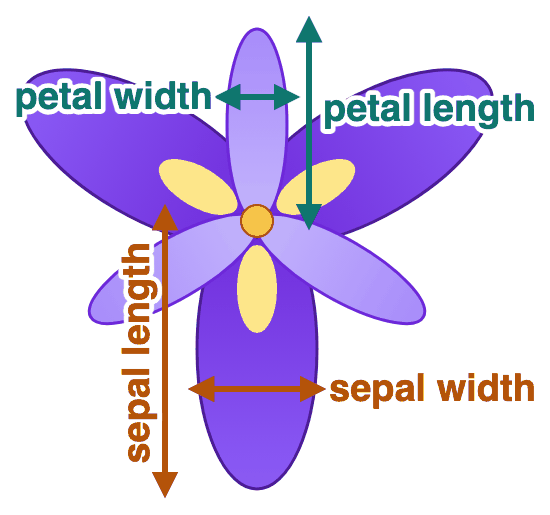<br>the 4 measurements</td>
  </tr>
</table>

**Sepals** are the 3 broad outer parts that bend outward; **petals** are the 3 narrow inner parts that stand up. Setosa petals are much shorter, so the two species are easy to separate. We keep the test split untouched in this guided demo.

<sub>Photos: <i>Iris setosa</i> by Radomil, <i>Iris versicolor</i> by Dlanglois; Wikimedia Commons, CC BY-SA 3.0.</sub>

In [ ]:
# Guided demo: reproducible data preparation and splitting
import numpy as np
from sklearn.datasets import load_iris

iris = load_iris()

# Inspect the original dataset before filtering
print("Original Iris dataset:")
print(f"Features: {iris.data.shape} with dtype {iris.data.dtype}")
print(f"Labels:   {iris.target.shape} with class counts {np.bincount(iris.target)}")
print("Classes:", list(iris.target_names))
print()

# Keep only setosa (0) and versicolor (1) and ignore virginica (2)
setosa_or_versicolor = iris.target < 2
data = iris.data[setosa_or_versicolor].astype(np.float32)
labels = iris.target[setosa_or_versicolor].astype(np.int64)

print("Dataset overview (after filtering):")
print("Source: Iris flowers, setosa vs versicolor")
print("Features:", list(iris.feature_names))
print("Classes:", list(iris.target_names[:2]))
print(f"Features: {data.shape} with dtype {data.dtype}")
print(f"Labels:   {labels.shape} with class counts {np.bincount(labels)}")
print("First three rows:\n", data[:3])
print("First three labels:", labels[:3])

num_samples = len(data)
# Shuffle 0, 1, ..., n-1. The seed makes this same shuffle repeatable.
indices = np.random.default_rng(42).permutation(num_samples)
train_end = int(0.60 * num_samples)
dev_end = int(0.80 * num_samples)

train_idx = indices[:train_end]
dev_idx = indices[train_end:dev_end]
test_idx = indices[dev_end:]

X_train, y_train = data[train_idx], labels[train_idx]
X_dev, y_dev = data[dev_idx], labels[dev_idx]
X_test, y_test = data[test_idx], labels[test_idx]

print("\nSplit shapes:")
print(f"train: X={X_train.shape}, y={y_train.shape}")
print(f"dev:   X={X_dev.shape}, y={y_dev.shape}")
print(f"test:  X={X_test.shape}, y={y_test.shape}")

Original Iris dataset:
Features: (150, 4) with dtype float64
Labels:   (150,) with class counts [50 50 50]
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Dataset overview (after filtering):
Source: Iris flowers, setosa vs versicolor
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor')]
Features: (100, 4) with dtype float32
Labels:   (100,) with class counts [50 50]
First three rows:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]]
First three labels: [0 0 0]

Split shapes:
train: X=(60, 4), y=(60,)
dev:   X=(20, 4), y=(20,)
test:  X=(20, 4), y=(20,)


In [ ]:
# @title Walkthrough: shuffle once, then cut the same index order into three splits
import numpy as np
from sklearn.datasets import load_iris

iris = load_iris()
setosa_or_versicolor = iris.target < 2

trace_code("""
num_samples = len(data)
indices = np.random.default_rng(42).permutation(num_samples)
train_end = int(0.60 * num_samples)
dev_end = int(0.80 * num_samples)

train_idx = indices[:train_end]
dev_idx = indices[train_end:dev_end]
test_idx = indices[dev_end:]

X_train, y_train = data[train_idx], labels[train_idx]
X_dev, y_dev = data[dev_idx], labels[dev_idx]
X_test, y_test = data[test_idx], labels[test_idx]
""", env={"np": np,
         "data": iris.data[setosa_or_versicolor].astype(np.float32),
         "labels": iris.target[setosa_or_versicolor].astype(np.int64)},
   title="Splitting into train / dev / test",
   notes={
       "num_samples = len": "{num_samples} examples in total.",
       "permutation": "A shuffled order of 0 … {num_samples - 1}. Seed 42 gives the same order every run.",
       "train_end = int": "60% of {num_samples}: train uses positions 0 … {train_end - 1} of indices.",
       "dev_end = int": "80%: dev uses positions {train_end} … {dev_end - 1}; test gets the rest.",
       "train_idx =": "The first {len(train_idx)} shuffled indices.",
       "dev_idx =": "The next {len(dev_idx)}.",
       "test_idx =": "The last {len(test_idx)}.",
       "X_train, y_train": "The SAME train_idx selects features and labels, so they stay paired: {X_train.shape} and {y_train.shape}.",
       "X_dev, y_dev": "Dev split: {X_dev.shape} and {y_dev.shape}.",
       "X_test, y_test": "Test split: {X_test.shape} and {y_test.shape}. We keep it untouched until the end.",
   })

### The model: forward and backward pass

The next cell trains a small multi-layer perceptron with the layers `4 → 8 → 2`:

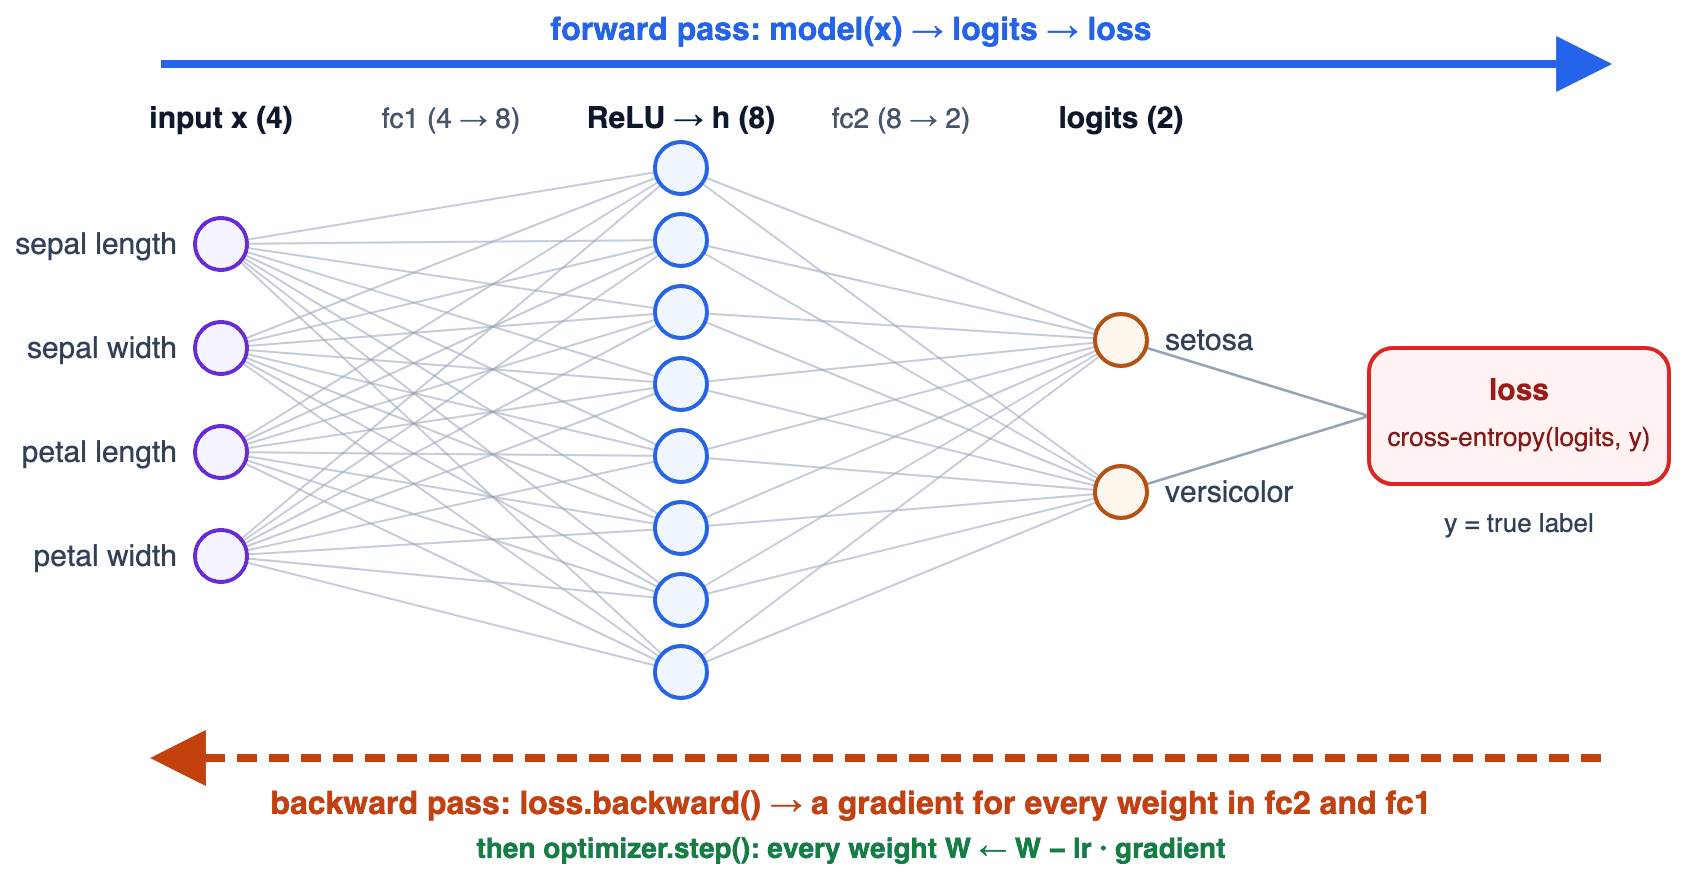

- **Forward pass** (blue): the 4 measurements flow through `fc1`, ReLU, and `fc2` to 2 class scores (logits); the loss compares them with the true label.
- **Backward pass** (orange): `loss.backward()` sends the error back through the same layers and gives every weight a gradient; `optimizer.step()` then updates the weights.

The first walkthrough after the next cell plays both passes for one flower with the real numbers.

In [ ]:
# Guided demo: one PyTorch optimization step
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris

# Data: the same setosa/versicolor flowers and the same train/dev split as in the cell above
X_train_tensor = torch.from_numpy(X_train)
y_train_tensor = torch.from_numpy(y_train)
X_dev_tensor = torch.from_numpy(X_dev)
y_dev_tensor = torch.from_numpy(y_dev)

torch.manual_seed(42)

class SimpleMLP(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_classes: int):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = self.fc1(x)
        hidden = self.relu(z)
        logits = self.fc2(hidden)
        return logits  # raw class scores (logits)

model = SimpleMLP(input_size=X_train_tensor.shape[1], hidden_size=8, num_classes=2)   # define the model
criterion = nn.CrossEntropyLoss()   # define the loss function
optimizer = optim.SGD(model.parameters(), lr=0.1)   # SGD = Stochastic Gradient Descent, lr = learning rate

model.train()
optimizer.zero_grad()                  # clear gradients from an earlier step
train_logits = model(X_train_tensor)   # forward pass
train_loss = criterion(train_logits, y_train_tensor)   # compute the loss
train_loss.backward()                  # compute parameter gradients
optimizer.step()                       # update parameters

model.eval()   # turn on model's evaluation mode, e.g., disabling dropout layers
with torch.no_grad():   # disable the calculation of gradients during evaluation
    dev_logits = model(X_dev_tensor)
    dev_predictions = dev_logits.argmax(dim=1)   # determine the class with max score as the prediction
    dev_accuracy = (dev_predictions == y_dev_tensor).float().mean().item()   # compare predictions with labels

print(model)
print(f"\nTraining logits shape: {tuple(train_logits.shape)}")
print(f"Loss for this optimization step: {train_loss.item():.4f}")
print(f"Development logits shape: {tuple(dev_logits.shape)}")
print(f"Development accuracy after one step: {dev_accuracy:.3f}")

assert train_logits.shape == (60, 2)
assert dev_logits.shape == (20, 2)
print("Check passed: one pair of logits was produced for every example.")

SimpleMLP(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=8, out_features=2, bias=True)
)

Training logits shape: (60, 2)
Loss for this optimization step: 2.0910
Development logits shape: (20, 2)
Development accuracy after one step: 0.600
Check passed: one pair of logits was produced for every example.


In [ ]:
# @title Walkthrough: forward and backward pass through the network for one flower
import numpy as np
import torch
from sklearn.datasets import load_iris

iris = load_iris()
setosa_or_versicolor = iris.target < 2
data = iris.data[setosa_or_versicolor].astype(np.float32)
labels = iris.target[setosa_or_versicolor].astype(np.int64)
flower = np.random.default_rng(42).permutation(len(data))[0]  # the first training flower

torch.manual_seed(42)  # same seed as above → the same untrained weights as the demo model
fresh_model = SimpleMLP(input_size=4, hidden_size=8, num_classes=2)  # the class from the cell above

network_walkthrough(fresh_model, data[flower], labels[flower], lr=0.1,
                    feature_names=["sepal length", "sepal width", "petal length", "petal width"],
                    class_names=["setosa", "versicolor"],
                    title="Forward and backward pass for one flower")

<string>:961: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)


In [ ]:
# @title Walkthrough: the same optimization step on a fresh copy of the model
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris

iris = load_iris()
setosa_or_versicolor = iris.target < 2
data = iris.data[setosa_or_versicolor].astype(np.float32)
labels = iris.target[setosa_or_versicolor].astype(np.int64)
indices = np.random.default_rng(42).permutation(len(data))
train_idx, dev_idx = indices[:60], indices[60:80]

torch.manual_seed(42)  # same seed as above → same initial weights, so the loss matches the printed one
walk_model = SimpleMLP(input_size=4, hidden_size=8, num_classes=2)  # the class from the cell above

trace_code("""
model.train()
optimizer.zero_grad()
train_logits = model(X_train_tensor)
train_loss = criterion(train_logits, y_train_tensor)
train_loss.backward()
optimizer.step()

model.eval()
with torch.no_grad():
    dev_logits = model(X_dev_tensor)
    dev_predictions = dev_logits.argmax(dim=1)
    dev_accuracy = (dev_predictions == y_dev_tensor).float().mean().item()
""", env={"torch": torch, "model": walk_model, "criterion": nn.CrossEntropyLoss(),
         "optimizer": optim.SGD(walk_model.parameters(), lr=0.1),
         "X_train_tensor": torch.from_numpy(data[train_idx]), "y_train_tensor": torch.from_numpy(labels[train_idx]),
         "X_dev_tensor": torch.from_numpy(data[dev_idx]), "y_dev_tensor": torch.from_numpy(labels[dev_idx])},
   watch=["train_logits", "train_loss", "model.fc2.weight.grad", "model.fc2.weight",
          "dev_logits", "dev_predictions", "dev_accuracy"],
   title="One optimization step: zero_grad → forward → loss → backward → step",
   intro="We watch the logits, the loss, and the output layer's weights and gradients.",
   notes={
       "model.train()": "Training mode (it matters for layers such as dropout; this MLP behaves the same).",
       "zero_grad": "Clears old gradients. This fresh model has none yet, so .grad is still None.",
       "train_logits = model": "Forward pass: shape {tuple(train_logits.shape)}, one pair of class scores per training example.",
       "train_loss = criterion": "Cross-entropy turns all logits and labels into ONE number: {train_loss.item():.4f}.",
       "backward": "Backpropagation fills .grad; it has the same shape as the weight.",
       "optimizer.step": "SGD update: weight ← weight − 0.1 · grad. Every highlighted cell moved.",
       "model.eval()": "Evaluation mode before measuring on the dev split.",
       "no_grad": "No gradients are needed for evaluation.",
       "dev_logits = model": "Forward pass on the {len(dev_logits)} dev examples.",
       "argmax": "argmax picks the class with the higher score for each dev example.",
       "dev_accuracy =": "Fraction of correct dev predictions: {dev_accuracy:.3f}.",
   })

---

## Task 2.1: Core array and tensor operations

**Goal:** practice the NumPy and PyTorch operations from the demo, with a focus on shapes, axes, and broadcasting.

Start from `arr = [[1, 2, 3], [4, 5, 6]]` with shape `(2, 3)`. **Before running**, predict the shape of every result in `predicted_shapes`. Then fill in the operations:

1. `flat`: `arr` as one vector of length 6;
2. `squared`: every entry of `arr` squared;
3. `product`: `arr` and the given matrix `W` multiplied with `@` (pick the order that works);
4. `row_means`: one mean per row of `arr`;
5. `A`: `arr` as a PyTorch tensor;
6. `broadcasted`: `A` plus the length-3 tensor `bias`, added to every row.

**Expected checks:** your predicted shapes match the real ones, the row means are `[2.0, 5.0]`, and every result has the expected values.

**Broadcasting:** shapes are aligned from the right, so `(2, 3) + (3,)` reuses the bias on every row: `[[1, 2, 3], [4, 5, 6]] + [10, 20, 30]` becomes `[[11, 22, 33], [14, 25, 36]]`.

In [ ]:
# Task 2.1: Complete the core array and tensor operations
import numpy as np
import torch

arr = np.array([[1, 2, 3], [4, 5, 6]])
W = np.array([[1, 0], [0, 1], [1, 1]])
bias = torch.tensor([10.0, 20.0, 30.0])

# Predict before you run: the shape of each result as a tuple, e.g. (2, 3)
predicted_shapes = {
    "flat": ___,
    "arr_T": ___,
    "product": ___,
    "row_means": ___,
    "broadcasted": ___,
}

flat = ___
squared = ___
arr_T = arr.T
product = ___
row_means = ___
A = ___
broadcasted = ___

print("Original:\n", arr)
print("Flat:", flat)
print("Squared:\n", squared)
print("Transpose:\n", arr_T)
print("Product:\n", product)
print("Row means:", row_means)
print("Broadcasted:\n", broadcasted)

actual_shapes = {"flat": flat.shape, "arr_T": arr_T.shape, "product": product.shape,
                 "row_means": row_means.shape, "broadcasted": tuple(broadcasted.shape)}
print("\nShape check (predicted -> actual):")
for name, shape in actual_shapes.items():
    print(f"  {name:12} {predicted_shapes[name]} -> {shape}")

assert predicted_shapes == actual_shapes, "At least one predicted shape is wrong: compare the shape check above."
assert np.array_equal(flat, [1, 2, 3, 4, 5, 6])
assert np.array_equal(squared, [[1, 4, 9], [16, 25, 36]])
assert np.array_equal(product, [[4, 5], [10, 11]])
assert np.allclose(row_means, [2.0, 5.0])
assert torch.equal(broadcasted, torch.tensor([[11.0, 22.0, 33.0], [14.0, 25.0, 36.0]]))
print("Check passed: shapes, matmul, axis reduction, and broadcasting behave as expected.")

---

## Task 2.2: Train a PyTorch MLP

**Goal:** complete the learning-specific parts of a small binary classifier; the data plumbing is provided.

The cell provides 50 Iris flowers (setosa vs versicolor, 4 features) split 40/10, a `4 → 8 → 2` MLP skeleton, `CrossEntropyLoss`, and SGD with learning rate `0.1` for 10 epochs.

Fill in the `___` placeholders:

1. the input and output sizes of `fc1` and `fc2`;
2. the forward pass: `fc1` → ReLU → `fc2`;
3. what the optimizer should update;
4. one optimization step inside the loop, **in the right order**: clear old gradients, forward pass, loss, backward pass, parameter update;
5. one predicted class per dev flower from the dev logits.

**Expected checks:** the dev logits have shape `(10, 2)`, the predictions have shape `(10,)`, and the final training loss is lower than the initial one.

In [ ]:
# Task 2.2: Complete a small PyTorch classifier
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.datasets import load_iris

# Provided data: Iris setosa vs versicolor (4 features), then a fixed 40/10 split
torch.manual_seed(42)
iris = load_iris()
setosa_or_versicolor = iris.target < 2  # 0 = setosa, 1 = versicolor
data = iris.data[setosa_or_versicolor].astype(np.float32)
labels = iris.target[setosa_or_versicolor].astype(np.int64)

indices = np.random.default_rng(42).permutation(len(data))[:50]
X_tensor = torch.from_numpy(data[indices])
y_tensor = torch.from_numpy(labels[indices])

X_train, y_train = X_tensor[:40], y_tensor[:40]
X_dev, y_dev = X_tensor[40:], y_tensor[40:]

class SimpleMLP(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_classes: int):
        super().__init__()
        self.fc1 = nn.Linear(___, ___)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(___, ___)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        hidden = ___
        logits = ___
        return logits

model = SimpleMLP(input_size=4, hidden_size=8, num_classes=2)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(___, lr=0.1)

model.eval()
with torch.no_grad():
    initial_loss = criterion(model(X_train), y_train).item()

model.train()
for epoch in range(10):
    optimizer.___()
    train_logits = ___
    loss = ___
    loss.___()
    ___.step()

    if epoch in {0, 4, 9}:
        print(f"Epoch {epoch + 1} | loss = {loss.item():.4f}")

model.eval()
with torch.no_grad():
    final_train_loss = criterion(model(X_train), y_train).item()
    dev_logits = model(X_dev)
    dev_predictions = ___
    dev_accuracy = (dev_predictions == y_dev).float().mean().item()

print(f"\nInitial training loss: {initial_loss:.4f}")
print(f"Final training loss:   {final_train_loss:.4f}")
print(f"Development accuracy:  {dev_accuracy:.3f}")

assert X_train.shape == (40, 4) and X_dev.shape == (10, 4)
assert dev_logits.shape == (10, 2)
assert dev_predictions.shape == (10,)
assert final_train_loss < initial_loss
print("Check passed: output shapes are correct and training loss decreased.")

## 8. Summary and final checks

You connected the main building blocks used throughout Intro2LLM:

- **Python control and text processing:** values, branches, loops, functions, slicing, splitting, and joining.
- **data structures and formats:** lists, dictionaries, files, CSV, and JSON.
- **numerical representations:** NumPy arrays, PyTorch tensors, shapes, axes, and broadcasting.
- **learning workflow:** train/development/test roles, logits, cross-entropy loss, gradients, parameter updates, and evaluation.

**Looking ahead:** later sessions replace whitespace tokens and synthetic features with linguistic preprocessing, learned representations, retrieval components, and LLM-based systems.